# Automotive Price Intelligence & Prediction

## Project Overview

This project uses historical automobile import data to analyse vehicle characteristics and predict automobile prices using machine learning regression techniques.

The project covers exploratory data analysis, data cleaning, feature preprocessing, model development, hyperparameter optimisation, model evaluation and prediction.

## Project Objective

The objective is to identify the vehicle characteristics associated with price variation and develop a reliable regression model that can help management understand automobile pricing patterns in a new market.

## Dataset Overview

- Dataset: 1985 Auto Imports Database
- Records: 201
- Total attributes: 26
- Independent variables: 25
- Target variable: `price`

## 1. Environment Setup and Data Loading

The project uses Python and its data science libraries to perform data analysis and develop machine learning models.

The dataset is loaded into a Pandas DataFrame. The original dataset contains automobile specifications and their corresponding prices.

The column names are assigned based on the dataset documentation, and missing values represented by `?` are interpreted as null values.

In [4]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python:", sys.version)
print("Environment:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
Environment: C:\Rakesh Project\Automotive-Price-Intelligence\.venv\Scripts\python.exe
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1


In [5]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# Locate the project containing the dataset.
current_path = Path.cwd().resolve()
search_paths = [current_path, *current_path.parents]
SOURCE_PROJECT_ROOT = next(
    (p for p in search_paths if (p / "data" / "raw" / "auto_imports.csv").exists()),
    None
)

if SOURCE_PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/raw/auto_imports.csv. "
        "Open this notebook from inside the improved project folder."
    )

# All generated files go into this separate folder.
PROJECT_ROOT = SOURCE_PROJECT_ROOT
DATA_PATH = SOURCE_PROJECT_ROOT / "data" / "raw" / "auto_imports.csv"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
MODEL_PATH = PROJECT_ROOT / "models"
VISUALIZATION_PATH = PROJECT_ROOT / "visualizations"
REPORT_PATH = PROJECT_ROOT / "reports"

for folder in [
    PROJECT_ROOT, PROCESSED_PATH, MODEL_PATH,
    VISUALIZATION_PATH, REPORT_PATH,
    PROJECT_ROOT / "src", PROJECT_ROOT / "tests",
    PROJECT_ROOT / "notebooks"
]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Dataset project root:", SOURCE_PROJECT_ROOT)
print("Improvement workspace:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("All generated outputs will be kept in the improvement workspace.")


Source project (read-only): C:\Rakesh Project\Automotive-Price-Intelligence
Improvement workspace: C:\Rakesh Project\Automotive-Evaluation-Improvements
Dataset exists: True
All generated outputs will be kept in the improvement workspace.


In [6]:
columns = [
    "symboling", "normalized_losses", "make", "fuel_type",
    "aspiration", "num_of_doors", "body_style", "drive_wheels",
    "engine_location", "wheel_base", "length", "width", "height",
    "curb_weight", "engine_type", "num_of_cylinders", "engine_size",
    "fuel_system", "bore", "stroke", "compression_ratio",
    "horsepower", "peak_rpm", "city_mpg", "highway_mpg", "price"
]

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully.
Shape: (201, 26)

Column names:
['symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration', 'num_of_doors', 'body_style', 'drive_wheels', 'engine_location', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_type', 'num_of_cylinders', 'engine_size', 'fuel_system', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg', 'price']

First 5 records:


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


## 2. Initial Data Inspection

The initial inspection examines the dataset structure, dimensions, column names, data types and basic statistical information.

This step helps identify the types of variables, understand the available data and detect potential data quality issues before performing detailed analysis.

In [7]:
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("MISSING VALUES BY COLUMN")
print("=" * 60)

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing[missing["Missing_Count"] > 0].sort_values(
    "Missing_Count", ascending=False
))

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Missing target prices:", df["price"].isnull().sum())
print("Unique manufacturers:", df["make"].nunique())
print("Unique car models by manufacturer:", df["make"].value_counts().to_dict())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               201 non-null    str    
 3   fuel_type          201 non-null    str    
 4   aspiration         201 non-null    str    
 5   num_of_doors       199 non-null    str    
 6   body_style         201 non-null    str    
 7   drive_wheels       201 non-null    str    
 8   engine_location    201 non-null    str    
 9   wheel_base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb_weight        201 non-null    int64  
 14  engine_type        201 non-null    str    
 15  num_of_cylinders   201 non-null    str    
 16  engine_size      

,Missing_Count,Missing_Percentage
normalized_losses,37,18.41
bore,4,1.99
stroke,4,1.99
num_of_doors,2,1.00
horsepower,2,1.00
peak_rpm,2,1.00



Total missing values: 51
Duplicate rows: 0
Missing target prices: 0
Unique manufacturers: 22
Unique car models by manufacturer: {'toyota': 32, 'nissan': 18, 'mazda': 17, 'honda': 13, 'mitsubishi': 13, 'subaru': 12, 'volkswagen': 12, 'peugot': 11, 'volvo': 11, 'dodge': 9, 'bmw': 8, 'mercedes-benz': 8, 'plymouth': 7, 'audi': 6, 'saab': 6, 'porsche': 4, 'alfa-romero': 3, 'chevrolet': 3, 'jaguar': 3, 'isuzu': 2, 'renault': 2, 'mercury': 1}


## 3. Dataset Composition and Feature Types

The dataset contains both numerical and categorical variables.

Numerical variables represent measurable vehicle characteristics, while categorical variables describe vehicle categories and specifications.

Separating these feature types helps select suitable analysis methods and preprocessing techniques for each group.

In [8]:
# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))

print("\nNUMERICAL SUMMARY")
display(df[numerical_columns].describe().T.round(2))

print("\nCATEGORICAL SUMMARY")
display(df[categorical_columns].describe().T)

print("\nTARGET VARIABLE – PRICE")
print("Minimum:", df["price"].min())
print("Maximum:", df["price"].max())
print("Mean:", round(df["price"].mean(), 2))
print("Median:", df["price"].median())
print("Standard Deviation:", round(df["price"].std(), 2))

Numerical columns: 16
Categorical columns: 10

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.84,1.25,-2.00,0.00,1.00,2.00,3.00
normalized_losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00
wheel_base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,174.20,12.32,141.10,166.80,173.20,183.50,208.10
width,201.0,65.89,2.10,60.30,64.10,65.50,66.60,72.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb_weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine_size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,197.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94
stroke,197.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17



CATEGORICAL SUMMARY


,count,unique,top,freq
make,201,22,toyota,32
fuel_type,201,2,gas,181
aspiration,201,2,std,165
num_of_doors,199,2,four,113
body_style,201,5,sedan,94
drive_wheels,201,3,fwd,118
engine_location,201,2,front,198
engine_type,201,6,ohc,145
num_of_cylinders,201,7,four,157
fuel_system,201,8,mpfi,92



TARGET VARIABLE – PRICE
Minimum: 5118
Maximum: 45400
Mean: 13207.13
Median: 10295.0
Standard Deviation: 7947.07


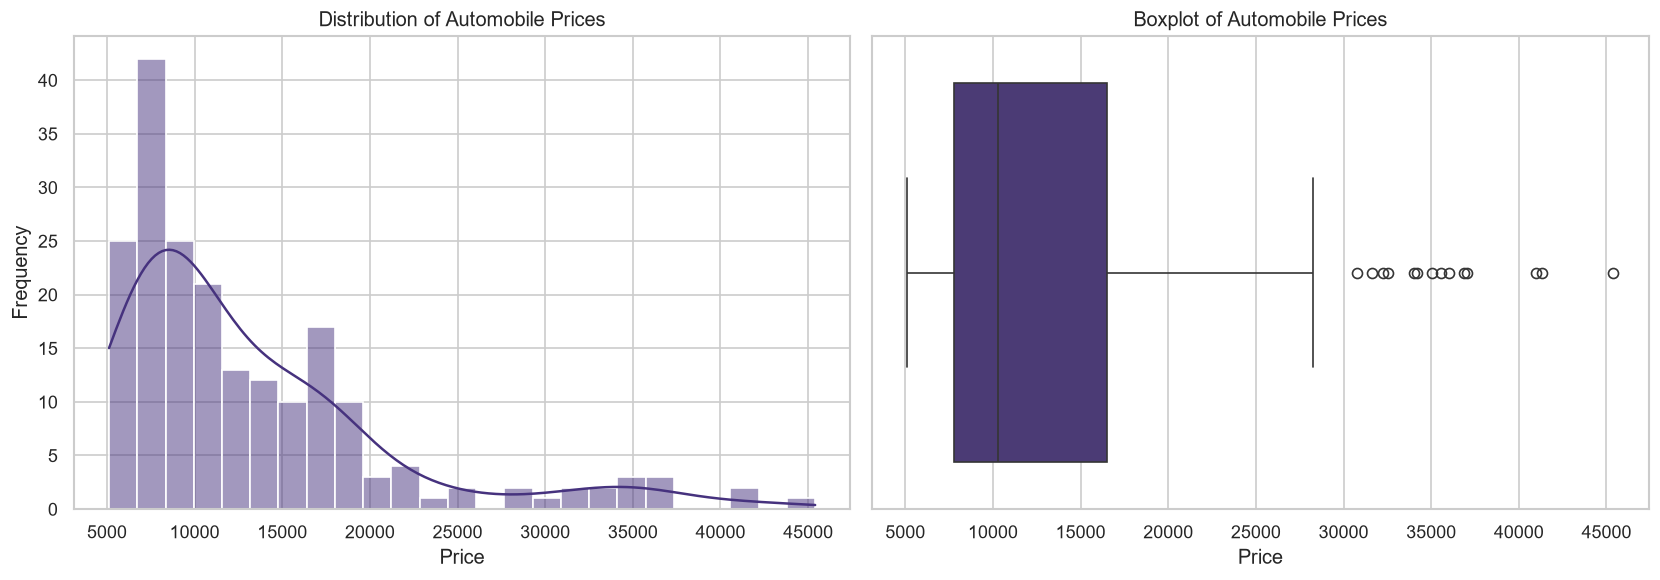

Price skewness: 1.81
Price kurtosis: 3.232


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["price"], kde=True, bins=25, ax=axes[0])
axes[0].set_title("Distribution of Automobile Prices")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=df["price"], ax=axes[1])
axes[1].set_title("Boxplot of Automobile Prices")
axes[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

print("Price skewness:", round(df["price"].skew(), 3))
print("Price kurtosis:", round(df["price"].kurtosis(), 3))

### Interpretation — Target Distribution

The following cell reports the observed skew and quantiles. Use these values to describe the shape and spread of the target; do not assume a normal distribution from the histogram alone.

In [10]:
price_skew = df["price"].skew()
print(f"Price skewness: {price_skew:.3f}")
print("Price quantiles:")
display(df["price"].quantile([0, .25, .50, .75, .90, .95, 1]).to_frame("Price").round(2))
if price_skew > 0.5:
    print("The observed target distribution is positively skewed; a smaller number of expensive vehicles extend the upper tail.")
elif price_skew < -0.5:
    print("The observed target distribution is negatively skewed.")
else:
    print("The observed target distribution is not strongly skewed by this descriptive threshold.")


Price skewness: 1.810
Price quantiles:


,Price
0.00,5118.0
0.25,7775.0
0.50,10295.0
0.75,16500.0
0.90,22470.0
0.95,32528.0
1.00,45400.0


The observed target distribution is positively skewed; a smaller number of expensive vehicles extend the upper tail.


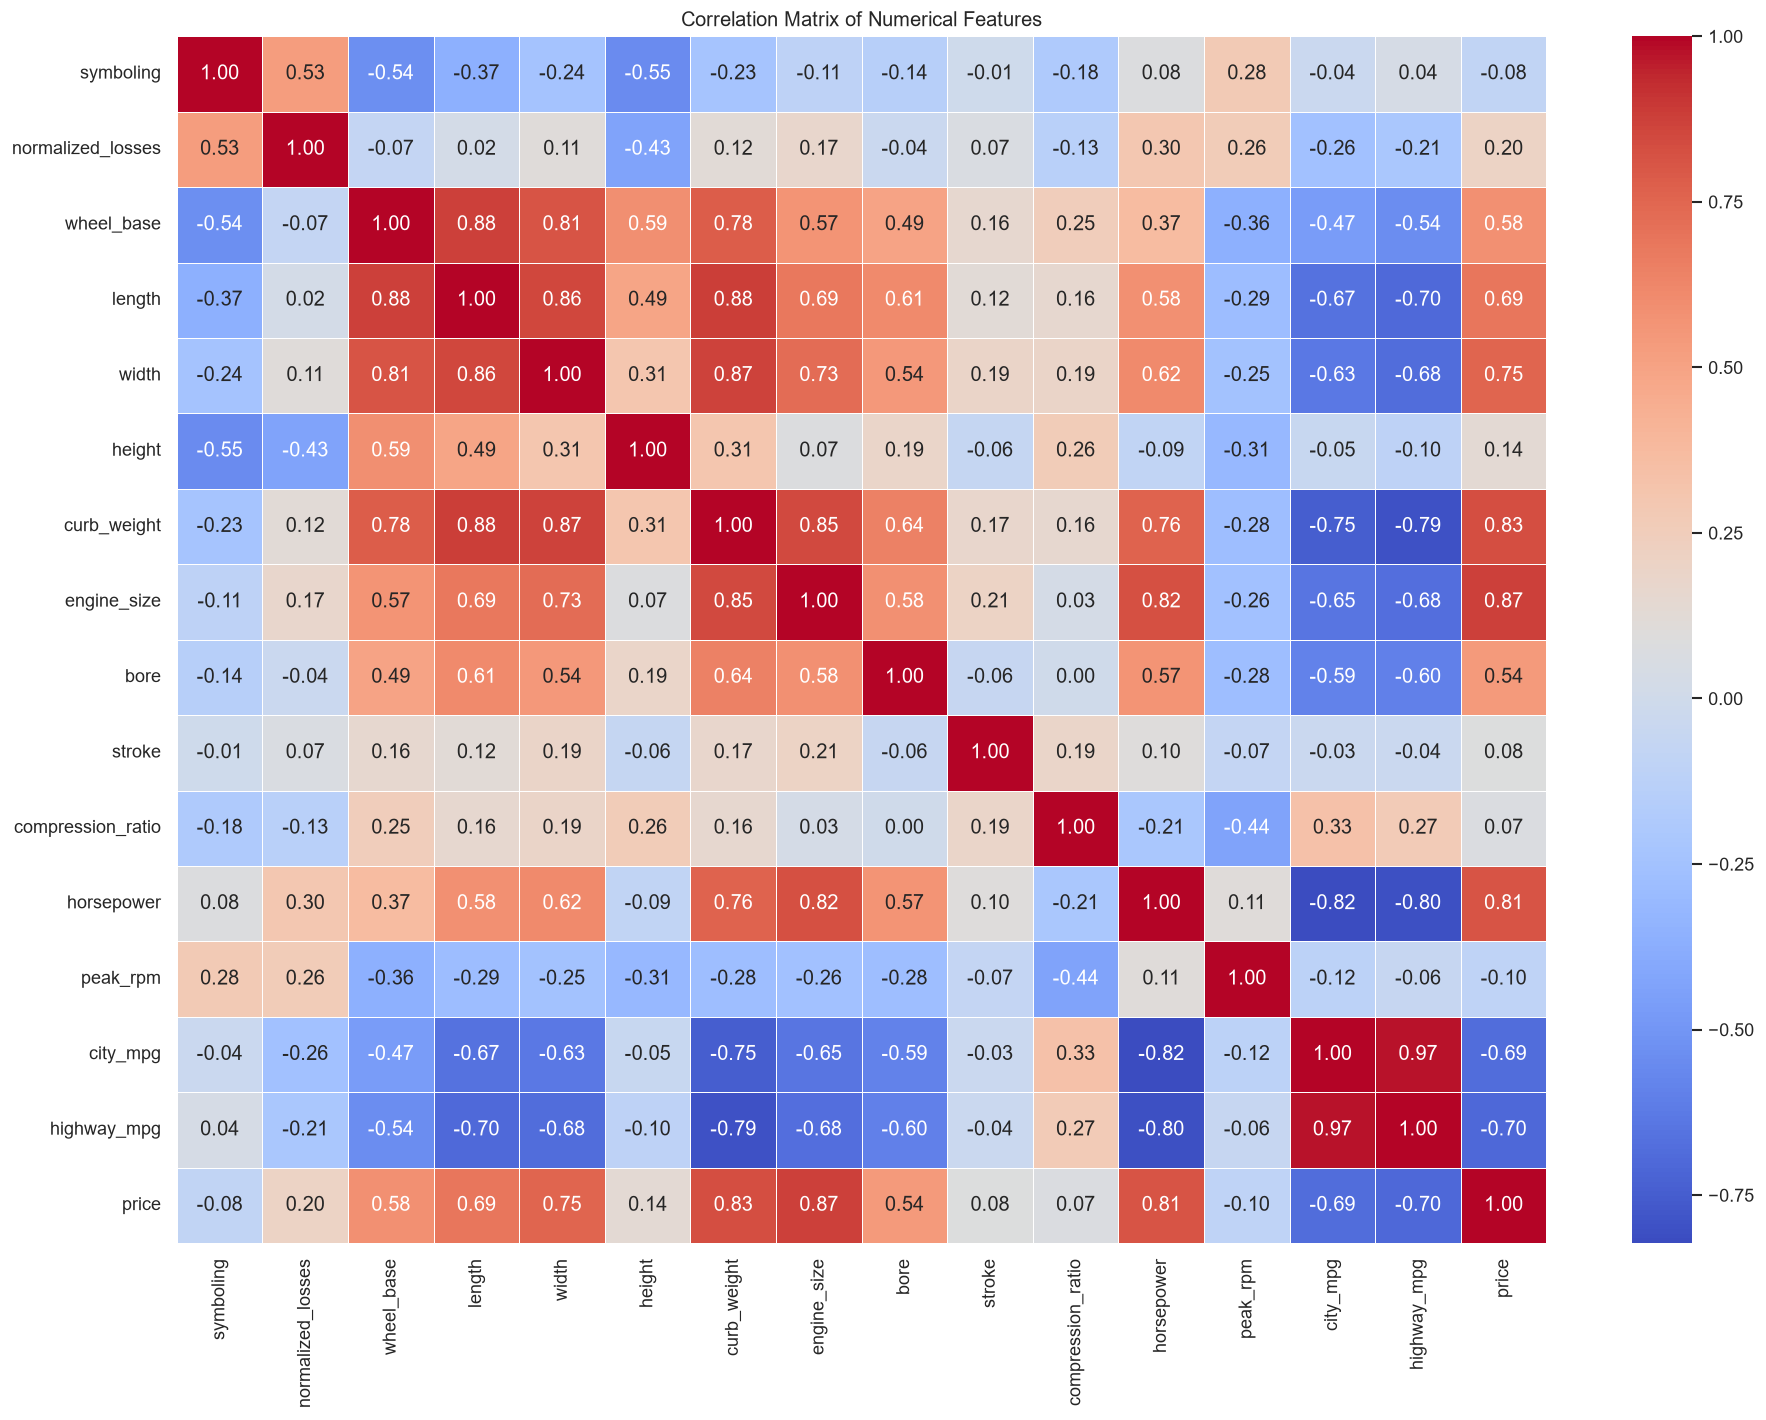


Top correlations with automobile price:


,Correlation_with_Price
engine_size,0.872335
curb_weight,0.834415
horsepower,0.810533
width,0.751265
highway_mpg,-0.704692
length,0.690628
city_mpg,-0.686571
wheel_base,0.584642
bore,0.543436
normalized_losses,0.203254


In [11]:
plt.figure(figsize=(16, 12))

correlation_matrix = df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.savefig(
    VISUALIZATION_PATH / "01_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nTop correlations with automobile price:")
display(
    correlation_matrix["price"]
    .drop("price")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation_with_Price")
)

### Interpretation — Numerical Correlations

Correlation describes association, not causation. Compare Pearson and Spearman results and consider whether a few influential observations or nonlinear monotonic relationships may affect the values.

In [12]:
price_corr = df[numerical_columns].corr(method="spearman")["price"].drop("price")
print("Three strongest absolute Spearman associations with price:")
display(price_corr.reindex(price_corr.abs().sort_values(ascending=False).head(3).index).to_frame("Spearman correlation").round(3))
print("These are exploratory associations; they do not establish that a feature causes a price change.")


Three strongest absolute Spearman associations with price:


,Spearman correlation
curb_weight,0.914
horsepower,0.851
city_mpg,-0.831


These are exploratory associations; they do not establish that a feature causes a price change.


## 4. Categorical Data Analysis

Categorical variables are analysed to understand the distribution of manufacturers, fuel types, body styles, drive systems and other vehicle characteristics.

Price differences across categorical groups are also examined to identify patterns in the historical automobile dataset.

Group-level price comparisons should be interpreted carefully, particularly where the number of observations is small.


MAKE – VALUE COUNTS


,Count
make,
toyota,32
nissan,18
mazda,17
honda,13
mitsubishi,13
subaru,12
volkswagen,12
peugot,11
volvo,11



FUEL_TYPE – VALUE COUNTS


,Count
fuel_type,
gas,181
diesel,20



ASPIRATION – VALUE COUNTS


,Count
aspiration,
std,165
turbo,36


... (10 outputs left out)


NUM_OF_CYLINDERS – VALUE COUNTS


,Count
num_of_cylinders,
four,157
six,24
five,10
two,4
eight,4
three,1
twelve,1



FUEL_SYSTEM – VALUE COUNTS


,Count
fuel_system,
mpfi,92
2bbl,64
idi,20
1bbl,11
spdi,9
4bbl,3
mfi,1
spfi,1


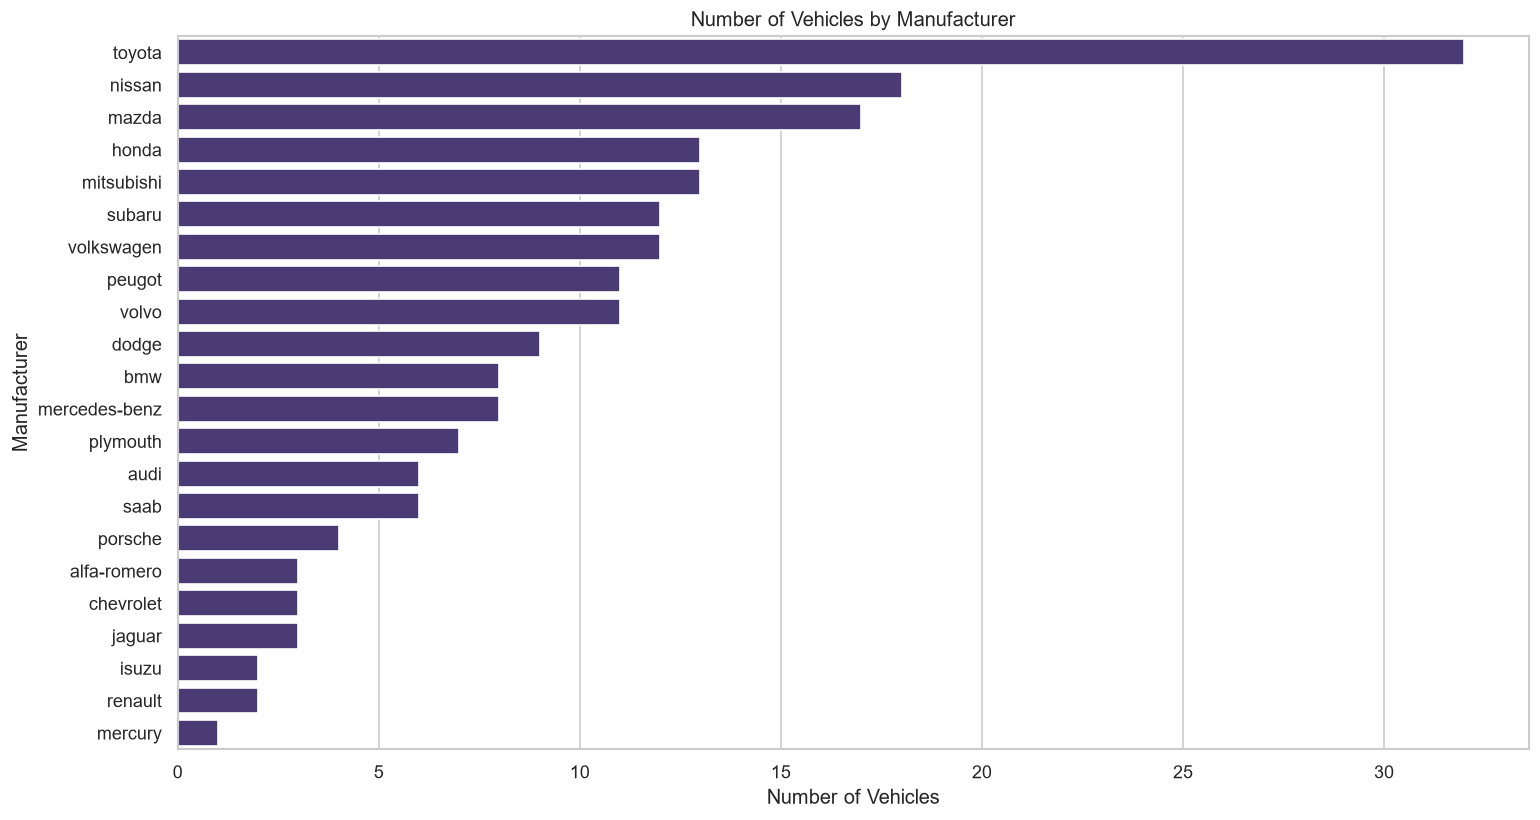

In [13]:
# Analyse manufacturer and categorical feature distributions

for column in categorical_columns:
    print(f"\n{'=' * 55}")
    print(f"{column.upper()} – VALUE COUNTS")
    print("=" * 55)
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("Count")
    )

# Save manufacturer distribution
plt.figure(figsize=(13, 7))

sns.countplot(
    data=df,
    y="make",
    order=df["make"].value_counts().index
)

plt.title("Number of Vehicles by Manufacturer")
plt.xlabel("Number of Vehicles")
plt.ylabel("Manufacturer")
plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "02_manufacturer_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation — Category Sample Sizes

Category counts matter when interpreting manufacturer and other categorical charts. Groups with very few records can produce unstable averages and medians.

In [14]:
for col in categorical_columns:
    counts = df[col].value_counts(dropna=False)
    print(f"\n{col}: {len(counts)} observed categories")
    display(counts.rename("Records").to_frame().head(15))
    small = counts[counts < 5]
    if len(small):
        print(f"Categories with fewer than 5 records: {len(small)}. Interpret their summaries cautiously.")



make: 22 observed categories


,Records
make,
toyota,32
nissan,18
mazda,17
honda,13
mitsubishi,13
subaru,12
volkswagen,12
peugot,11
volvo,11


Categories with fewer than 5 records: 7. Interpret their summaries cautiously.

fuel_type: 2 observed categories


,Records
fuel_type,
gas,181
diesel,20



aspiration: 2 observed categories


,Records
aspiration,
std,165
turbo,36


... (11 outputs left out)

,Records
num_of_cylinders,
four,157
six,24
five,10
two,4
eight,4
three,1
twelve,1


Categories with fewer than 5 records: 4. Interpret their summaries cautiously.

fuel_system: 8 observed categories


,Records
fuel_system,
mpfi,92
2bbl,64
idi,20
1bbl,11
spdi,9
4bbl,3
mfi,1
spfi,1


Categories with fewer than 5 records: 3. Interpret their summaries cautiously.


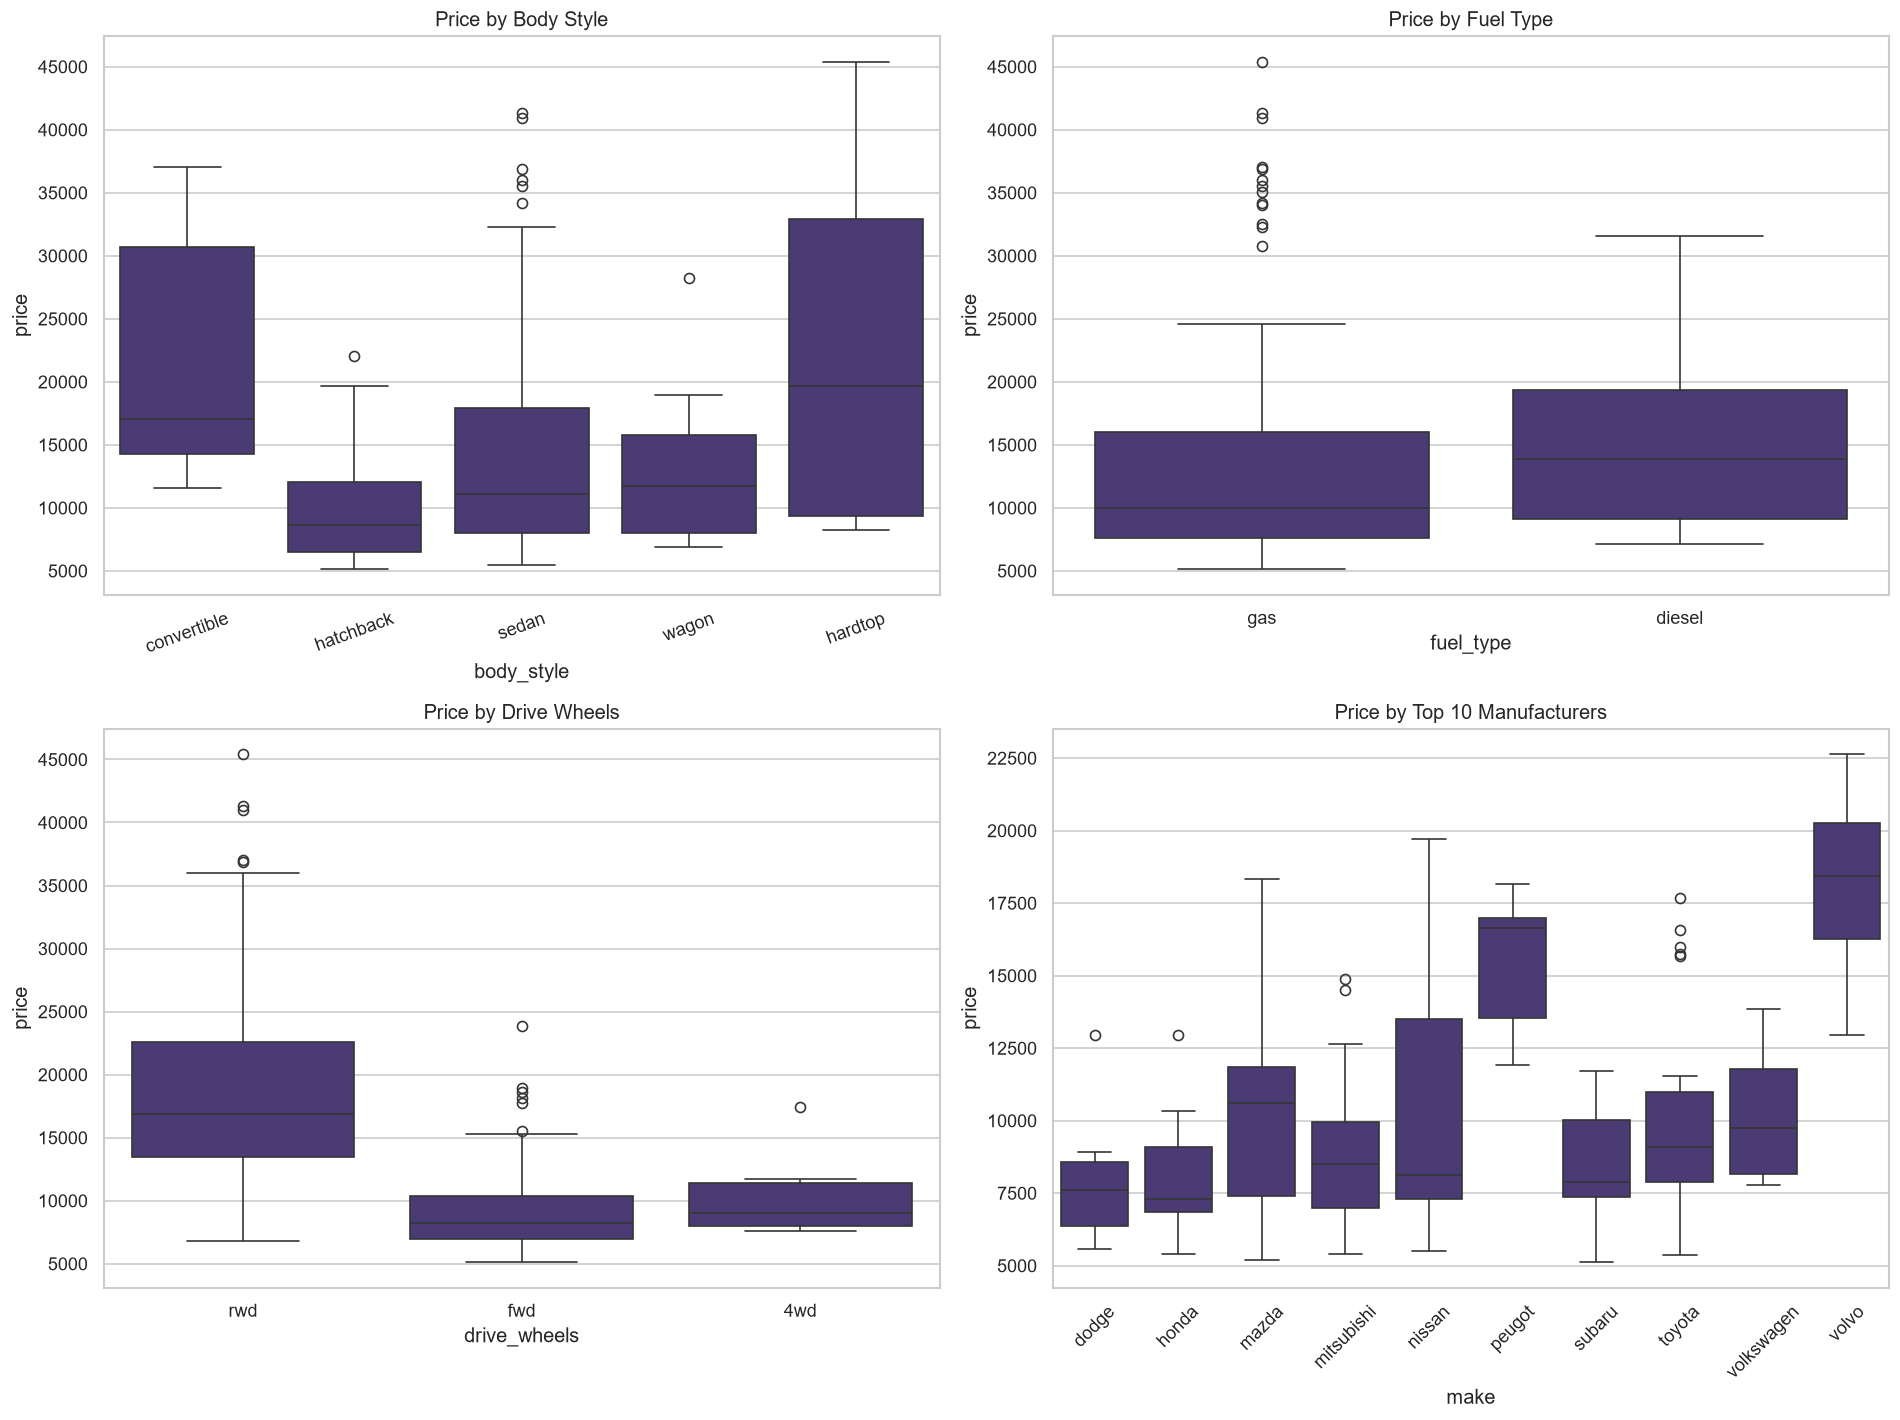

Median price by body style:


,count,median,mean
body_style,,,
convertible,6,17084.5,21890.50
hardtop,8,19687.5,22208.50
hatchback,68,8672.0,9957.44
sedan,94,11078.5,14459.76
wagon,25,11694.0,12371.96



Median price by manufacturer (top 10 by record count):


,count,median,mean
make,,,
volvo,11,18420.0,18063.18
peugot,11,16630.0,15489.09
mazda,17,10595.0,10652.88
volkswagen,12,9737.5,10077.50
toyota,32,9103.0,9885.81
mitsubishi,13,8499.0,9239.77
nissan,18,8124.0,10415.67
subaru,12,7894.0,8541.25
dodge,9,7609.0,7875.44


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.boxplot(data=df, x="body_style", y="price", ax=axes[0, 0])
axes[0, 0].set_title("Price by Body Style")
axes[0, 0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="fuel_type", y="price", ax=axes[0, 1])
axes[0, 1].set_title("Price by Fuel Type")

sns.boxplot(data=df, x="drive_wheels", y="price", ax=axes[1, 0])
axes[1, 0].set_title("Price by Drive Wheels")

top_manufacturers = df["make"].value_counts().head(10).index

sns.boxplot(
    data=df[df["make"].isin(top_manufacturers)],
    x="make",
    y="price",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Price by Top 10 Manufacturers")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "03_categorical_price_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Median price by body style:")
display(df.groupby("body_style")["price"].agg(["count", "median", "mean"]).round(2))

print("\nMedian price by manufacturer (top 10 by record count):")
display(
    df[df["make"].isin(top_manufacturers)]
    .groupby("make")["price"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
    .round(2)
)

### Interpretation — Price Across Categories

Use both the group count and price distribution. A difference in medians is descriptive; small groups and overlapping distributions do not support strong claims of statistical significance.

In [16]:
for col in ["body_style", "fuel_type", "drive_wheels", "engine_type", "aspiration"]:
    print(f"\nPrice summary by {col}:")
    summary = df.groupby(col, dropna=False)["price"].agg(
        Count="count", Median="median", Mean="mean", Std_Dev="std"
    ).sort_values("Median", ascending=False)
    display(summary.round(2))
    print("Groups with fewer than 5 records should be treated as low-confidence descriptive comparisons.")



Price summary by body_style:


,Count,Median,Mean,Std_Dev
body_style,,,,
hardtop,8,19687.5,22208.50,14555.52
convertible,6,17084.5,21890.50,11187.80
wagon,25,11694.0,12371.96,5120.95
sedan,94,11078.5,14459.76,8523.21
hatchback,68,8672.0,9957.44,4148.86


Groups with fewer than 5 records should be treated as low-confidence descriptive comparisons.

Price summary by fuel_type:


,Count,Median,Mean,Std_Dev
fuel_type,,,,
diesel,20,13852.5,15838.15,7759.84
gas,181,9989.0,12916.41,7934.92


Groups with fewer than 5 records should be treated as low-confidence descriptive comparisons.

Price summary by drive_wheels:


,Count,Median,Mean,Std_Dev
drive_wheels,,,,
rwd,75,16900.0,19757.61,9082.58
4wd,8,9005.5,10241.00,3288.21
fwd,118,8192.0,9244.78,3345.90


Groups with fewer than 5 records should be treated as low-confidence descriptive comparisons.

Price summary by engine_type:


,Count,Median,Mean,Std_Dev
engine_type,,,,
ohcv,13,19699.0,25098.38,11442.93
dohc,12,16249.0,18116.42,7963.96
l,12,16105.0,14627.58,3673.60
rotor,4,12745.0,13020.00,2079.06
ohcf,15,9233.0,13738.60,10930.48
ohc,145,9095.0,11567.36,6445.41


Groups with fewer than 5 records should be treated as low-confidence descriptive comparisons.

Price summary by aspiration:


,Count,Median,Mean,Std_Dev
aspiration,,,,
turbo,36,15686.0,16254.81,6179.62
std,165,9538.0,12542.18,8147.75


Groups with fewer than 5 records should be treated as low-confidence descriptive comparisons.


## 5. Numerical Data Analysis

Numerical variables are examined using descriptive statistics and distribution plots.

This analysis helps understand the range, central tendency, spread and distribution of vehicle characteristics such as engine size, horsepower, vehicle dimensions, weight and fuel efficiency.

Understanding these distributions helps identify unusual observations and potential preprocessing requirements.

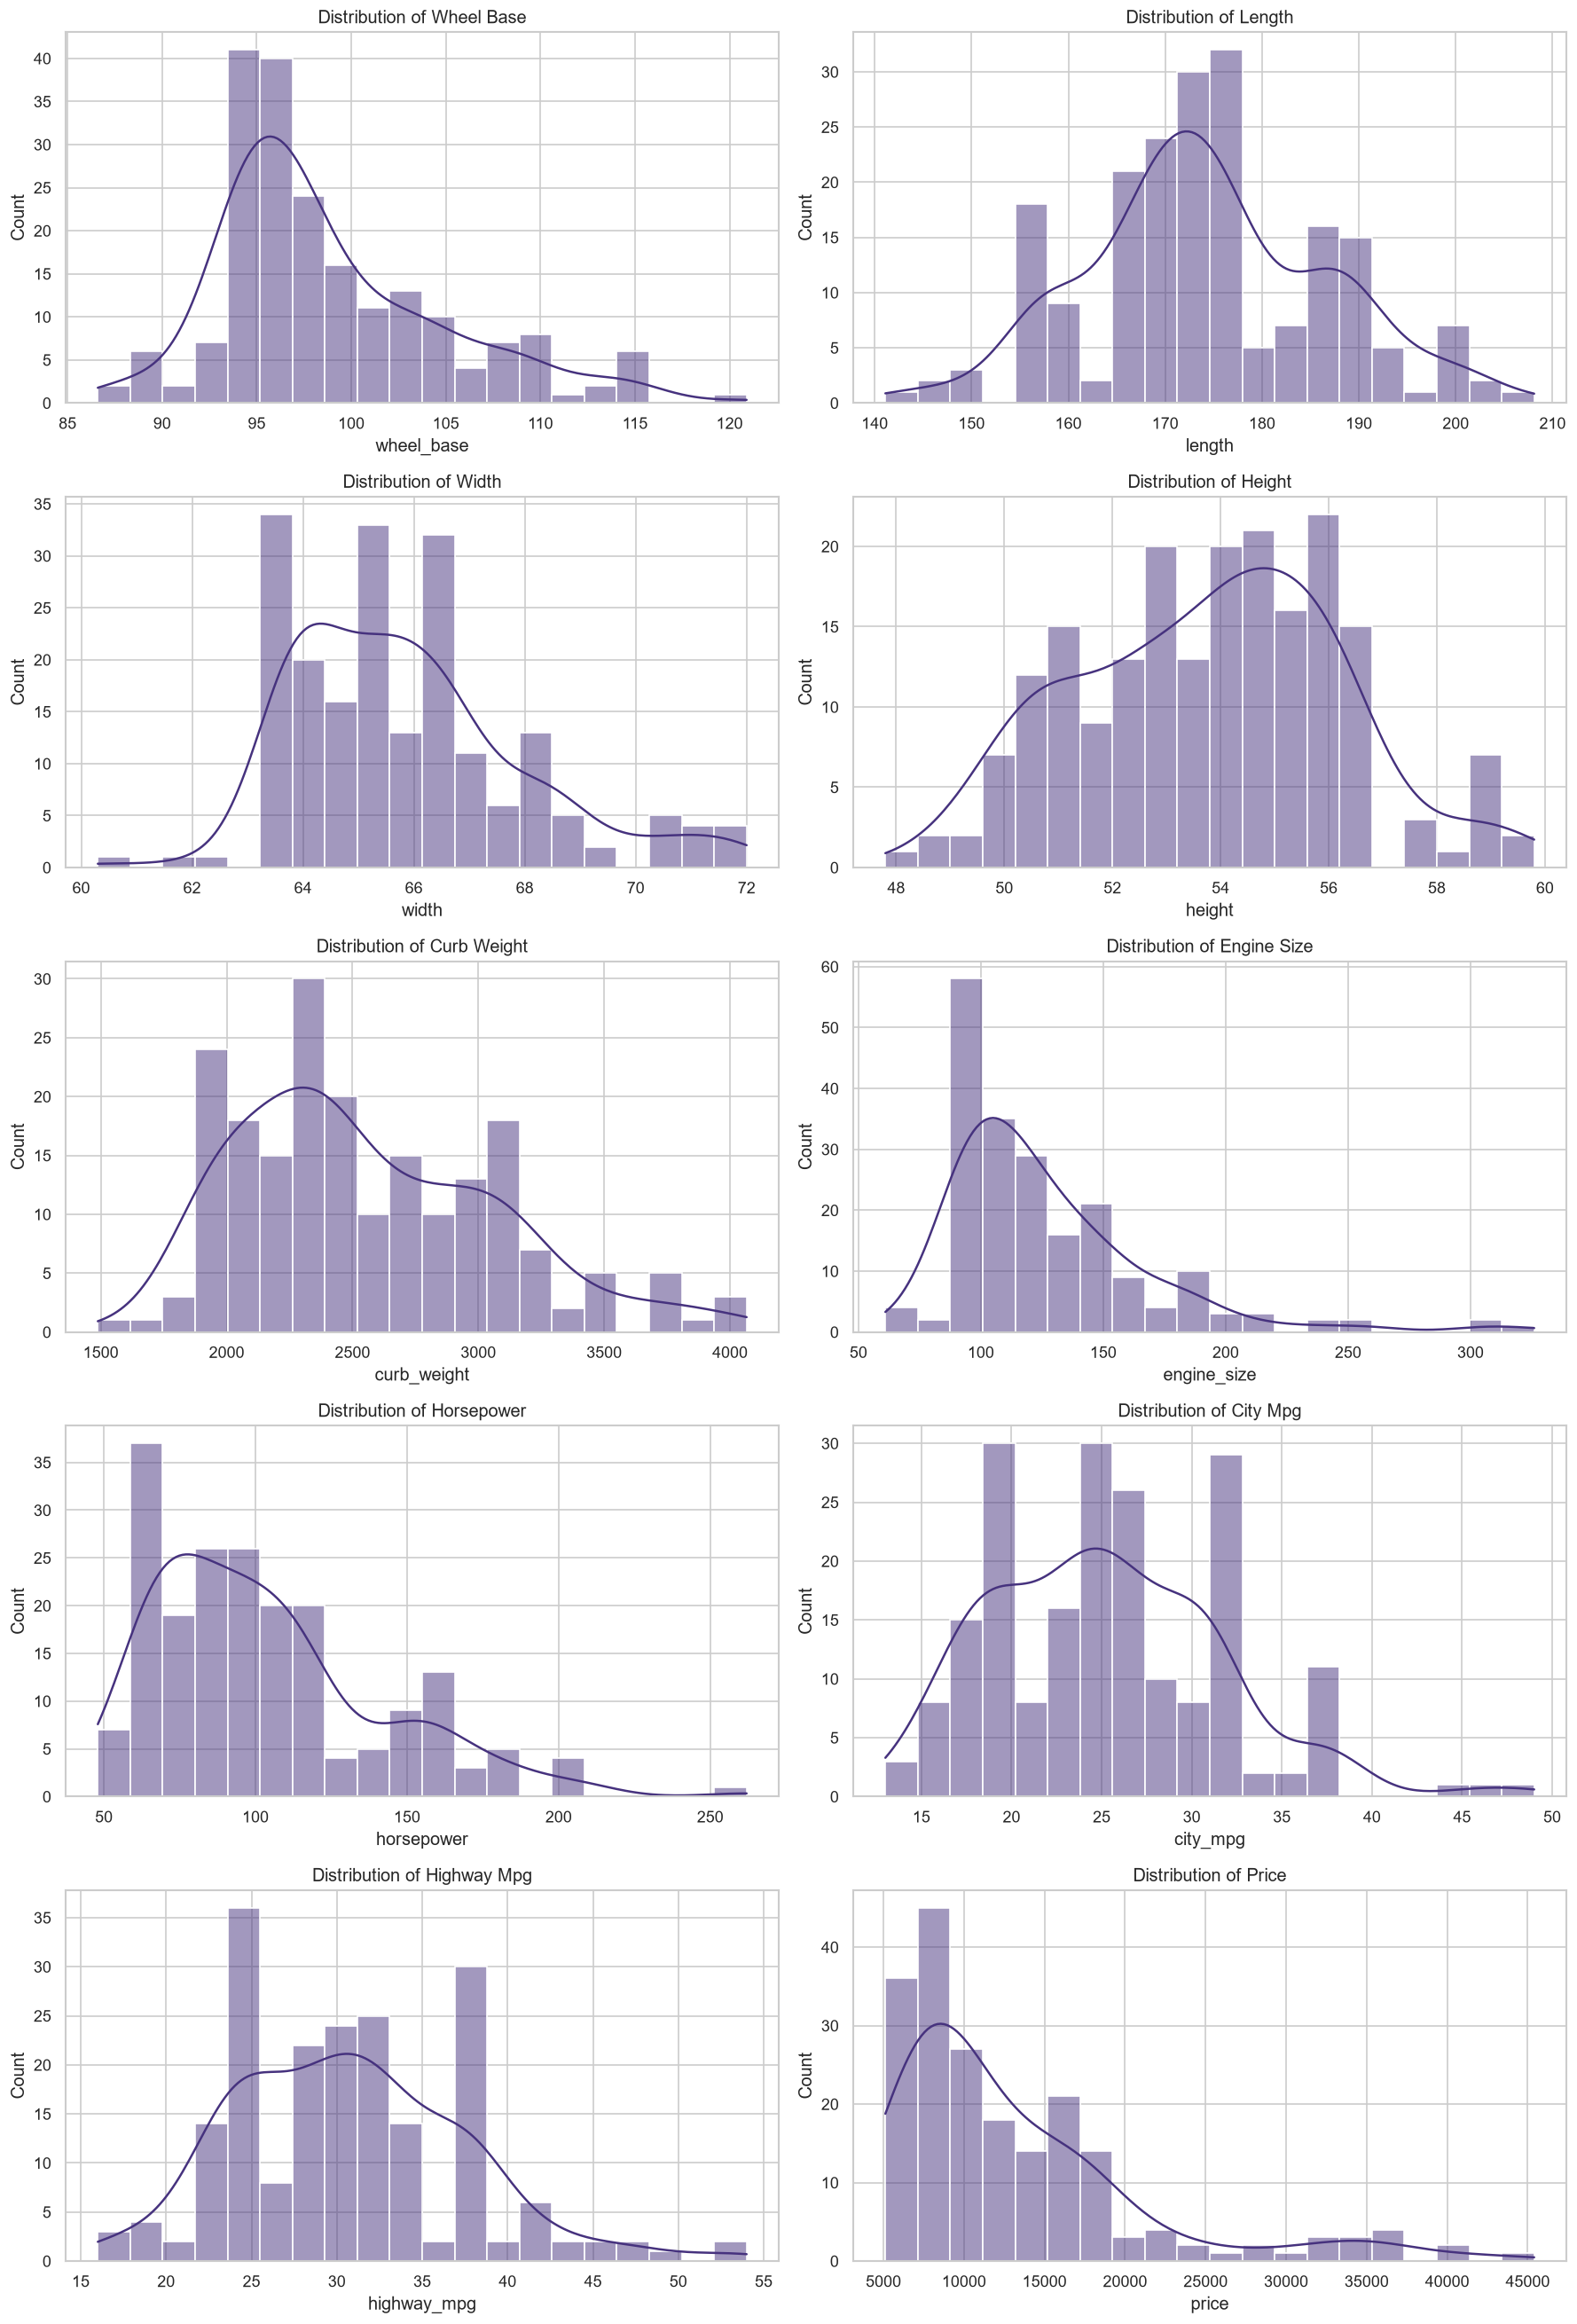

In [17]:
# Distribution plots for numerical variables

plot_columns = [
    "wheel_base", "length", "width", "height",
    "curb_weight", "engine_size", "horsepower",
    "city_mpg", "highway_mpg", "price"
]

fig, axes = plt.subplots(5, 2, figsize=(15, 22))

for column, ax in zip(plot_columns, axes.flatten()):
    sns.histplot(df[column], kde=True, ax=ax, bins=20)
    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "04_numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation — Numerical Feature Distributions

Skewness is reported below to identify numerical features with asymmetric distributions. This is a diagnostic; transformations should be justified and compared inside the training-validation process.

In [18]:
numeric_skew = df[numerical_columns].skew().sort_values(key=abs, ascending=False)
display(numeric_skew.to_frame("Skewness").round(3))
print("High absolute skewness can indicate asymmetric distributions or influential observations; it does not by itself require transformation.")


,Skewness
compression_ratio,2.584
engine_size,1.979
price,1.810
horsepower,1.142
wheel_base,1.031
width,0.875
normalized_losses,0.766
curb_weight,0.706
stroke,-0.694
city_mpg,0.680


High absolute skewness can indicate asymmetric distributions or influential observations; it does not by itself require transformation.


## 6. Outlier Analysis

Potential outliers in automobile prices are examined using the Interquartile Range (IQR) method.

The analysis identifies observations with unusually high or low values relative to the overall price distribution.

High-priced vehicles are investigated to determine whether they represent possible data errors or genuine premium and high-performance automobiles.

Valid observations are retained rather than automatically removed, as they may contain important pricing information.

In [19]:
outlier_results = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ).sum()

    outlier_results.append({
        "Feature": column,
        "Lower_Limit": round(lower_limit, 2),
        "Upper_Limit": round(upper_limit, 2),
        "Outlier_Count": int(outlier_count)
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        "Outlier_Count", ascending=False
    ).reset_index(drop=True)
)

,Feature,Lower_Limit,Upper_Limit,Outlier_Count
0,compression_ratio,7.40,10.60,27
1,stroke,2.66,3.86,20
2,price,-5312.50,29587.50,14
3,width,60.35,70.35,11
4,engine_size,33.50,205.50,10
5,horsepower,1.00,185.00,5
6,wheel_base,82.65,114.25,3
7,highway_mpg,11.50,47.50,3
8,curb_weight,1033.50,4061.50,2
9,city_mpg,2.50,46.50,2


### Interpretation — IQR Outlier Screening

IQR flags identify unusual values, not necessarily errors. Review feature context and plausible vehicle specifications before removing any record.

In [20]:
display(outlier_df.sort_values("Outlier_Count", ascending=False).head(10))
print("No observations are removed solely because they fall outside an IQR fence.")


,Feature,Lower_Limit,Upper_Limit,Outlier_Count
10,compression_ratio,7.40,10.60,27
9,stroke,2.66,3.86,20
15,price,-5312.50,29587.50,14
4,width,60.35,70.35,11
7,engine_size,33.50,205.50,10
11,horsepower,1.00,185.00,5
2,wheel_base,82.65,114.25,3
14,highway_mpg,11.50,47.50,3
6,curb_weight,1033.50,4061.50,2
13,city_mpg,2.50,46.50,2


No observations are removed solely because they fall outside an IQR fence.


In [21]:
# Examine the 14 potential price outliers

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

upper_price_limit = Q3 + 1.5 * IQR

high_price_cars = df[df["price"] > upper_price_limit].sort_values(
    "price", ascending=False
)

print("Upper price outlier threshold:", upper_price_limit)
print("Number of high-priced vehicles:", len(high_price_cars))

display(
    high_price_cars[
        ["make", "body_style", "fuel_type", "engine_size",
         "horsepower", "curb_weight", "price"]
    ]
)

Upper price outlier threshold: 29587.5
Number of high-priced vehicles: 14


,make,body_style,fuel_type,engine_size,horsepower,curb_weight,price
71,mercedes-benz,hardtop,gas,304,184.0,3715,45400
15,bmw,sedan,gas,209,182.0,3380,41315
70,mercedes-benz,sedan,gas,308,184.0,3900,40960
125,porsche,convertible,gas,194,207.0,2800,37028
16,bmw,sedan,gas,209,182.0,3505,36880
46,jaguar,sedan,gas,326,262.0,3950,36000
45,jaguar,sedan,gas,258,176.0,4066,35550
69,mercedes-benz,convertible,gas,234,155.0,3685,35056
68,mercedes-benz,sedan,gas,234,155.0,3740,34184
124,porsche,hardtop,gas,194,207.0,2756,34028


## 7. Missing Value Analysis

Missing values are examined across the dataset to identify incomplete vehicle records and determine which features require preprocessing.

The supplied dataset contains missing values in several independent variables, including normalized losses, number of doors, bore, stroke, horsepower and peak RPM.

The target variable, price, contains no missing values in the supplied CSV file.

Missing values are handled later through preprocessing pipelines using median imputation for numerical variables and most-frequent-value imputation for categorical variables.

In [22]:
# Missing-value analysis

missing_rows = df[df.isnull().any(axis=1)]

print("Records containing missing values:", len(missing_rows))
print("Total missing cells:", df.isnull().sum().sum())

print("\nMissing values by manufacturer:")
display(
    missing_rows.groupby("make")
    .agg(
        Records_With_Missing=("make", "size"),
        Missing_Values=("make", lambda x: df.loc[x.index].isnull().sum().sum())
    )
    .sort_values("Missing_Values", ascending=False)
)

print("\nMissing-value combinations:")
display(
    df[df.isnull().any(axis=1)]
    [["make", "normalized_losses", "num_of_doors",
      "bore", "stroke", "horsepower", "peak_rpm"]]
    .head(20)
)

Records containing missing values: 42
Total missing cells: 51

Missing values by manufacturer:


,Records_With_Missing,Missing_Values
make,,
mazda,6,11
renault,2,6
peugot,4,4
bmw,4,4
volkswagen,4,4
mitsubishi,3,3
mercedes-benz,3,3
alfa-romero,3,3
porsche,3,3



Missing-value combinations:


,make,normalized_losses,num_of_doors,bore,stroke,horsepower,peak_rpm
0,alfa-romero,NaN,two,3.47,2.68,111.0,5000.0
1,alfa-romero,NaN,two,3.47,2.68,111.0,5000.0
2,alfa-romero,NaN,two,2.68,3.47,154.0,5000.0
5,audi,NaN,two,3.19,3.40,110.0,5500.0
7,audi,NaN,four,3.19,3.40,110.0,5500.0
13,bmw,NaN,four,3.31,3.19,121.0,4250.0
14,bmw,NaN,four,3.62,3.39,182.0,5400.0
15,bmw,NaN,two,3.62,3.39,182.0,5400.0
16,bmw,NaN,four,3.62,3.39,182.0,5400.0
26,dodge,148.0,NaN,3.03,3.39,102.0,5500.0


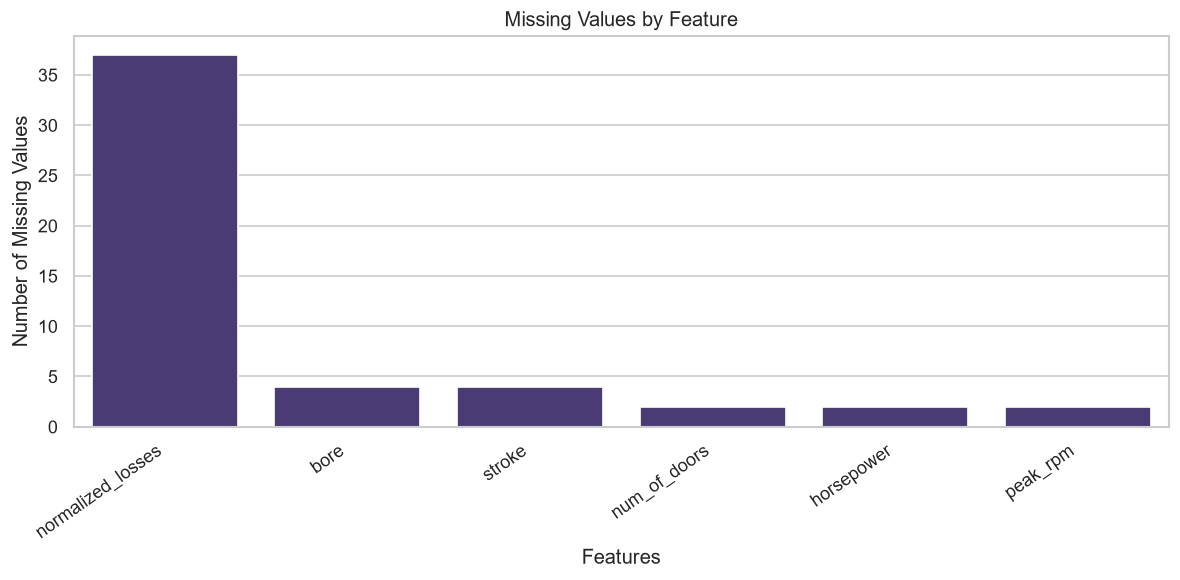

In [23]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_counts.index,
    y=missing_counts.values
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "05_missing_values_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation — Missingness

Missing-value counts are reported by feature. The imputation strategy is fitted within each cross-validation training fold to prevent validation information from influencing imputation values.

In [24]:
missing_summary = df.isnull().sum().to_frame("Missing_Count")
missing_summary["Missing_Percent"] = missing_summary["Missing_Count"] / len(df) * 100
display(missing_summary[missing_summary["Missing_Count"] > 0].sort_values("Missing_Percent", ascending=False).round(2))


,Missing_Count,Missing_Percent
normalized_losses,37,18.41
bore,4,1.99
stroke,4,1.99
num_of_doors,2,1.00
horsepower,2,1.00
peak_rpm,2,1.00


## 8. Feature Relationships with Vehicle Price

The relationships between numerical vehicle characteristics and automobile prices are examined using scatter plots and correlation analysis.

Pearson correlation measures the strength and direction of linear relationships, while Spearman correlation helps identify monotonic relationships that may not be strictly linear.

These analyses help identify features that may contain useful information for predicting automobile prices.

Correlation indicates association and does not establish causation.

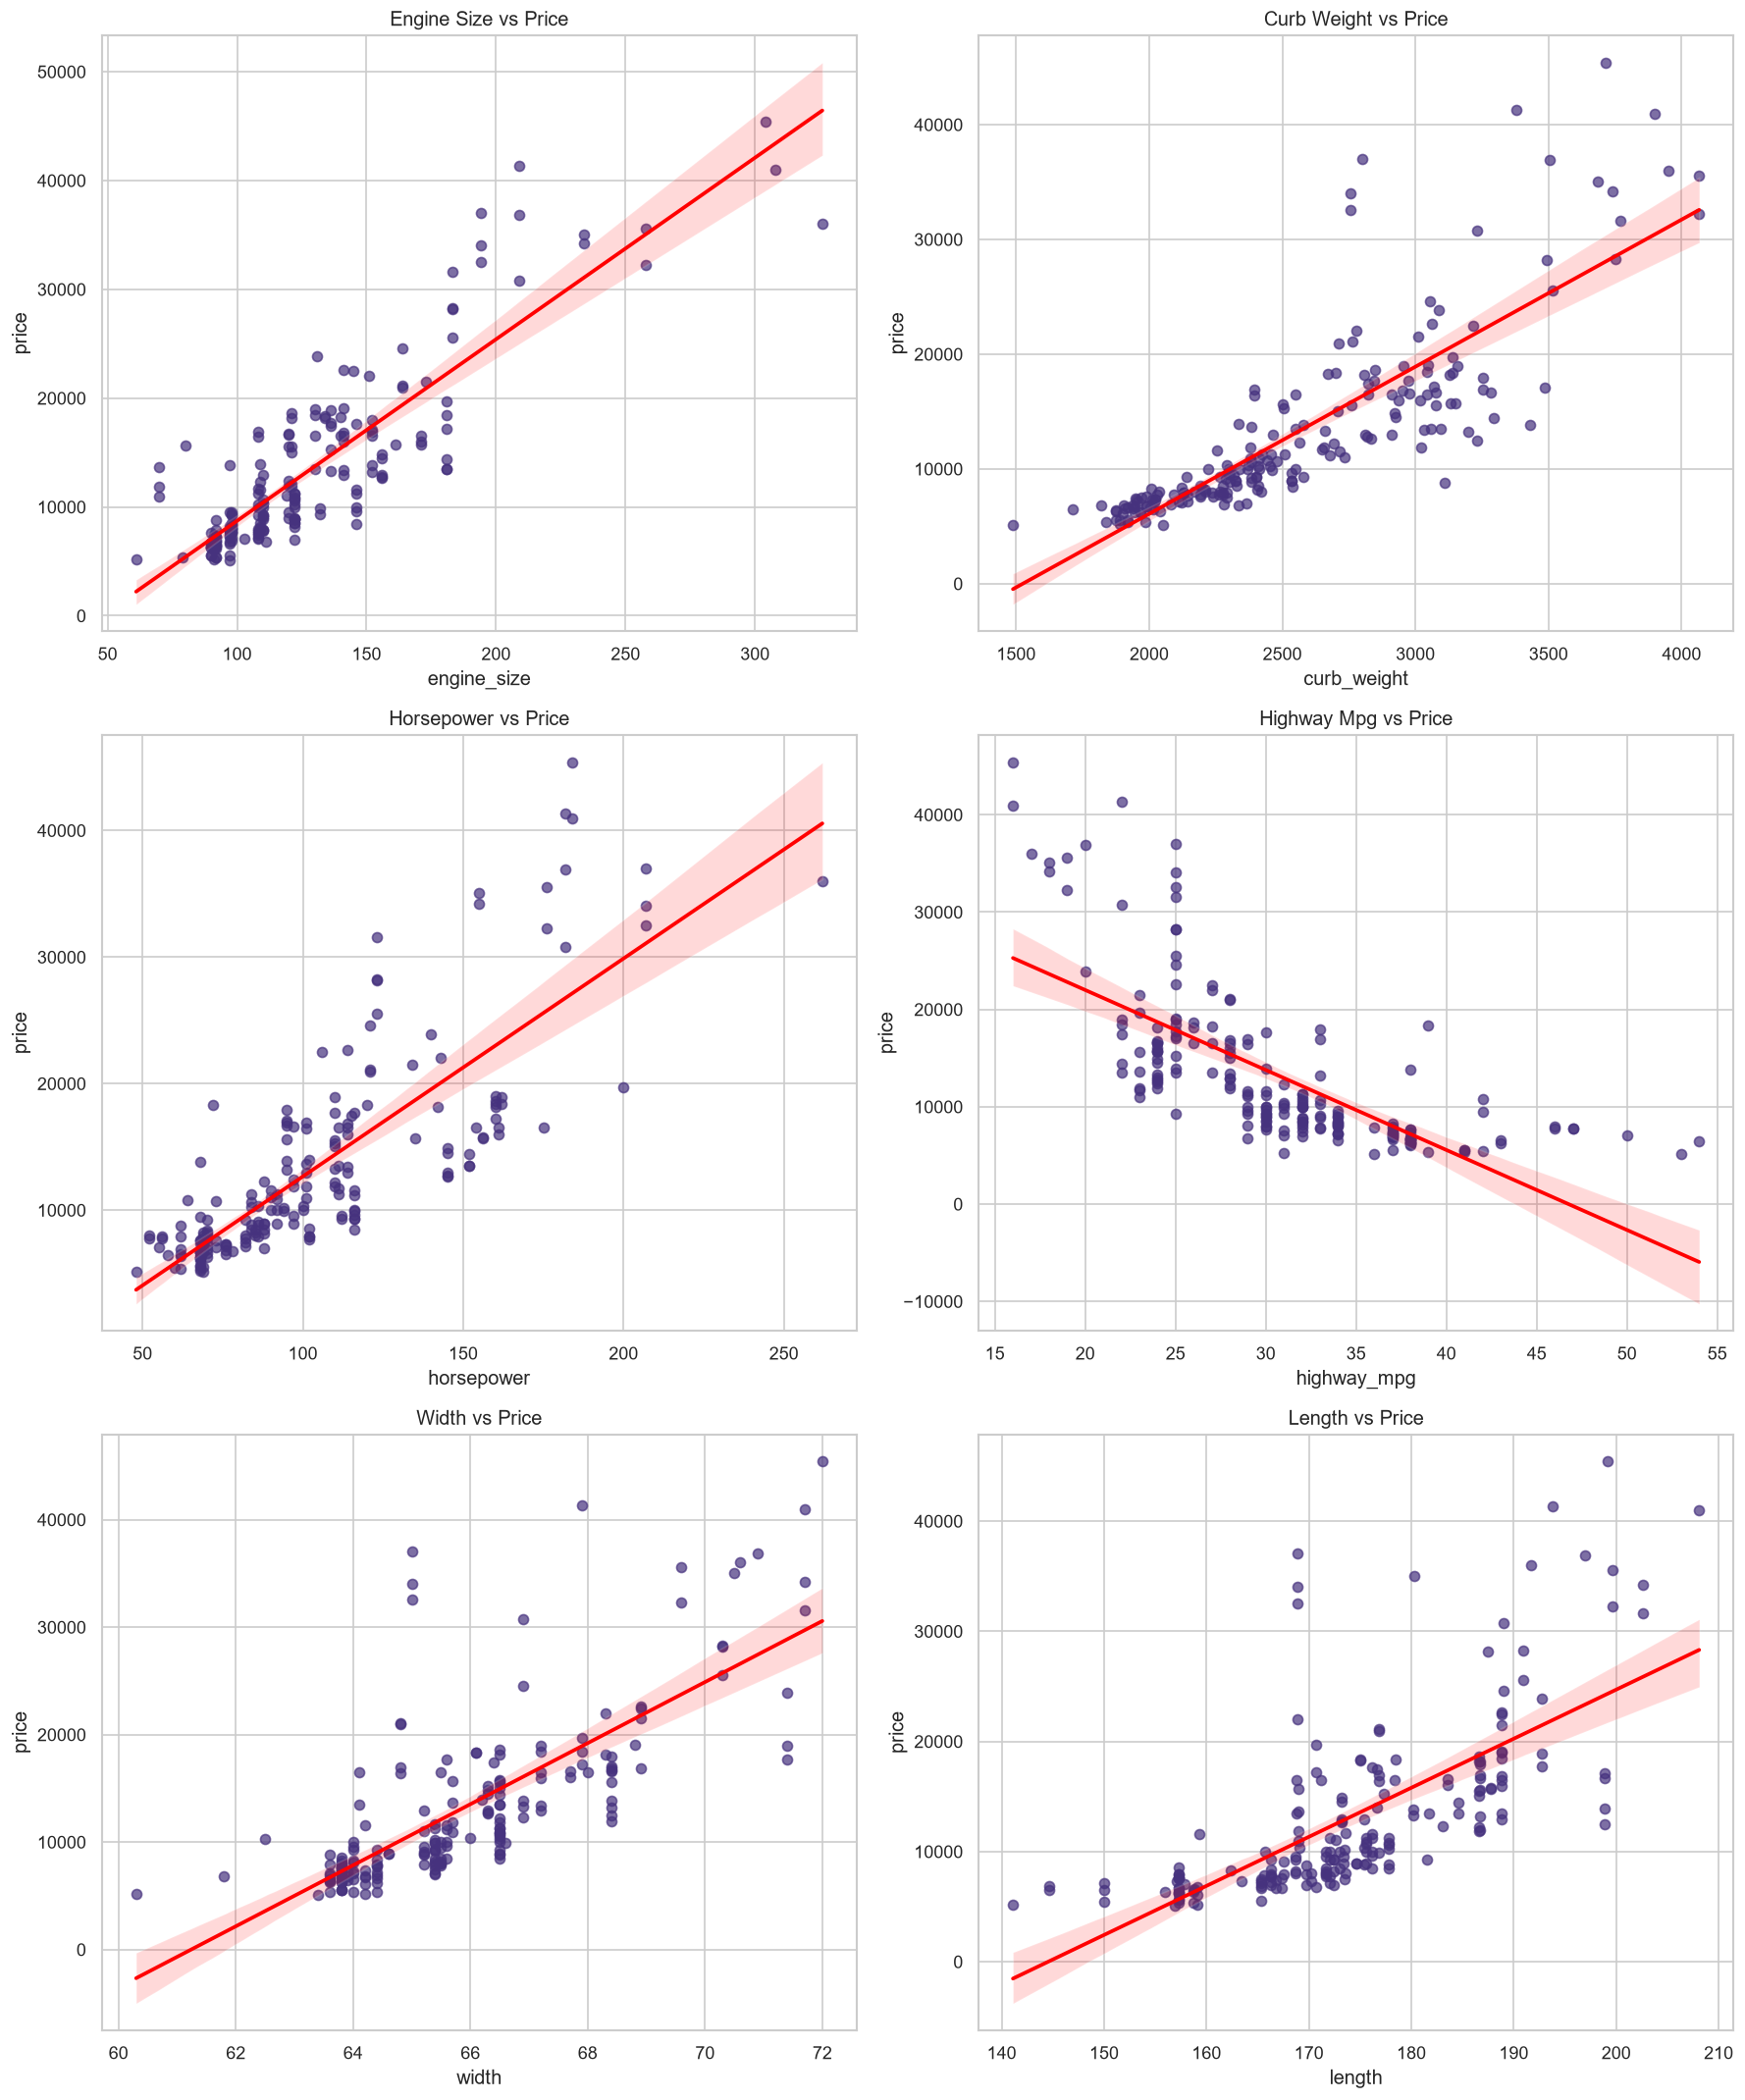

In [25]:
# Relationship between key numerical features and vehicle price

key_features = [
    "engine_size",
    "curb_weight",
    "horsepower",
    "highway_mpg",
    "width",
    "length"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 18))

for feature, ax in zip(key_features, axes.flatten()):
    sns.regplot(
        data=df,
        x=feature,
        y="price",
        ax=ax,
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )
    ax.set_title(f"{feature.replace('_', ' ').title()} vs Price")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "06_numerical_features_vs_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation — Feature/Price Relationships

Inspect scatter patterns for curvature, changing spread and influential observations. A fitted trend line is descriptive and does not establish causality.

In [26]:
relationship_summary = df[key_features + ["price"]].corr(method="spearman")["price"].drop("price")
display(relationship_summary.reindex(relationship_summary.abs().sort_values(ascending=False).index).to_frame("Spearman correlation with price").round(3))


,Spearman correlation with price
curb_weight,0.914
horsepower,0.851
engine_size,0.828
highway_mpg,-0.827
width,0.812
length,0.810


In [27]:
# Spearman correlation with vehicle price

spearman_correlations = (
    df[numerical_columns]
    .corr(method="spearman")["price"]
    .drop("price")
    .sort_values(key=abs, ascending=False)
)

display(
    spearman_correlations.to_frame(
        name="Spearman_Correlation_with_Price"
    ).round(3)
)

,Spearman_Correlation_with_Price
curb_weight,0.914
horsepower,0.851
city_mpg,-0.831
engine_size,0.828
highway_mpg,-0.827
width,0.812
length,0.810
wheel_base,0.682
bore,0.649
height,0.264


In [28]:
# Compare Pearson and Spearman correlations

correlation_comparison = pd.DataFrame({
    "Pearson": df[numerical_columns].corr()["price"].drop("price"),
    "Spearman": df[numerical_columns].corr(method="spearman")["price"].drop("price")
})

correlation_comparison["Difference"] = (
    correlation_comparison["Spearman"] -
    correlation_comparison["Pearson"]
)

display(
    correlation_comparison
    .sort_values("Spearman", key=abs, ascending=False)
    .round(3)
)

,Pearson,Spearman,Difference
curb_weight,0.834,0.914,0.079
horsepower,0.811,0.851,0.040
city_mpg,-0.687,-0.831,-0.145
engine_size,0.872,0.828,-0.044
highway_mpg,-0.705,-0.827,-0.123
width,0.751,0.812,0.061
length,0.691,0.810,0.120
wheel_base,0.585,0.682,0.097
bore,0.543,0.649,0.106
height,0.135,0.264,0.128


## 9. Multicollinearity Analysis

Multicollinearity occurs when two or more independent variables are strongly related to one another.

Variance Inflation Factor (VIF) is used to examine multicollinearity among numerical features.

The analysis identifies substantial overlap among certain vehicle characteristics, particularly vehicle size, weight and fuel-efficiency variables.

This is considered during model selection. Regularised regression models and tree-based algorithms are evaluated to understand how different modelling approaches handle these relationships.

In [29]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Prepare numerical predictors
vif_data = df[numerical_columns].drop(columns=["price"]).dropna()

# Add intercept
vif_matrix = add_constant(vif_data)

# Calculate VIF
vif_results = pd.DataFrame({
    "Feature": vif_matrix.columns,
    "VIF": [
        variance_inflation_factor(vif_matrix.values, i)
        for i in range(vif_matrix.shape[1])
    ]
})

vif_results = vif_results[vif_results["Feature"] != "const"]

display(
    vif_results.sort_values("VIF", ascending=False).round(2)
)

,Feature,VIF
14,city_mpg,25.80
15,highway_mpg,23.35
7,curb_weight,16.82
8,engine_size,9.00
4,length,8.22
3,wheel_base,8.18
12,horsepower,7.23
5,width,6.09
6,height,2.73
11,compression_ratio,2.58


## 10. Exploratory Data Analysis Summary

The exploratory analysis highlights several important patterns:

- Automobile prices vary considerably across the supplied records.
- Engine size, curb weight, horsepower and vehicle dimensions show strong associations with price.
- Fuel-efficiency variables generally show negative associations with price in this dataset.
- Manufacturer and body-style groups demonstrate differences in their observed price distributions.
- Missing values and multicollinearity require appropriate preprocessing and model evaluation.

These findings guide the subsequent feature preparation and regression modelling stages.

In [30]:
# Final EDA summary for numerical features

eda_summary = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Std_Dev": df[numerical_columns].std(),
    "Missing_Count": df[numerical_columns].isnull().sum(),
    "Pearson_Correlation": df[numerical_columns].corr()["price"],
    "Spearman_Correlation": df[numerical_columns].corr(
        method="spearman"
    )["price"]
})

display(
    eda_summary
    .drop(index="price")
    .round(3)
    .sort_values(
        "Spearman_Correlation",
        key=abs,
        ascending=False
    )
)

,Mean,Median,Std_Dev,Missing_Count,Pearson_Correlation,Spearman_Correlation
curb_weight,2555.667,2414.00,517.297,0,0.834,0.914
horsepower,103.397,95.00,37.554,2,0.811,0.851
city_mpg,25.179,24.00,6.423,0,-0.687,-0.831
engine_size,126.876,120.00,41.547,0,0.872,0.828
highway_mpg,30.687,30.00,6.815,0,-0.705,-0.827
width,65.889,65.50,2.101,0,0.751,0.812
length,174.201,173.20,12.322,0,0.691,0.810
wheel_base,98.797,97.00,6.066,0,0.585,0.682
bore,3.331,3.31,0.271,4,0.543,0.649
height,53.767,54.10,2.448,0,0.135,0.264


## 11. Feature and Target Preparation

The target variable is `price`, which represents the automobile price to be predicted.

The remaining 25 columns are treated as independent variables.

The feature matrix and target series are prepared separately to establish the inputs and expected output for supervised regression modelling.

In [31]:
# Separate features and target variable

X = df.drop(columns=["price"]).copy()
y = df["price"].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget variable:")
print("Name:", y.name)
print("Missing values:", y.isnull().sum())

print("\nFeature types:")
print("Numerical features:", X.select_dtypes(include=np.number).shape[1])
print("Categorical features:", X.select_dtypes(exclude=np.number).shape[1])

print("\nMissing values in features:")
display(
    X.isnull().sum()[X.isnull().sum() > 0]
)

Feature matrix shape: (201, 25)
Target vector shape: (201,)

Target variable:
Name: price
Missing values: 0

Feature types:
Numerical features: 15
Categorical features: 10

Missing values in features:


normalized_losses    37
num_of_doors          2
bore                  4
stroke                4
horsepower            2
peak_rpm              2
dtype: int64

## 12. Training and Testing Data Split

The dataset is divided into training and testing subsets using an 80:20 split.

A fixed random state is used to make the split reproducible.

The training data is used to develop and optimise the models, while the independent test data is reserved for final performance evaluation.

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining price statistics:")
display(y_train.describe().round(2))

print("\nTesting price statistics:")
display(y_test.describe().round(2))


Training features: (160, 25)
Testing features: (41, 25)

Training target: (160,)
Testing target: (41,)

Training price statistics:


count      160.00
mean     12573.68
std       6775.93
min       5118.00
25%       7796.25
50%      10470.00
75%      16500.00
max      45400.00
Name: price, dtype: float64


Testing price statistics:


count       41.00
mean     15679.12
std      11198.46
min       5572.00
25%       7689.00
50%       9988.00
75%      18150.00
max      41315.00
Name: price, dtype: float64

## 13. Data Preprocessing

A preprocessing pipeline is developed to handle numerical and categorical variables.

Numerical features are processed using median imputation and standard scaling.

Categorical features are processed using most-frequent-value imputation and one-hot encoding.

The preprocessing steps are integrated with the machine learning models using Scikit-learn pipelines.

This approach ensures that preprocessing is fitted using training data within the cross-validation process and helps prevent data leakage.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical features: 15
Categorical features: 10
Preprocessing pipeline created successfully.


In [34]:
# Leakage control: do not fit the preprocessor separately here.
# Each model Pipeline fits its own cloned preprocessor using only that fold's
# training rows during cross-validation, and the full training set during refit.
# The untouched test set is transformed only when the selected pipeline predicts it.

print("Preprocessor remains unfitted outside the model pipelines.")
print("Training-fold-only preprocessing will be enforced by scikit-learn Pipeline.")


Preprocessor remains unfitted outside the model pipelines.
Training-fold-only preprocessing will be enforced by scikit-learn Pipeline.


## 14. Baseline Model

A Dummy Regressor is developed as a baseline model.

It predicts the mean target value rather than learning relationships between vehicle characteristics and price.

The baseline provides a reference point for determining whether the machine learning models deliver meaningful improvements over a simple prediction strategy.

In [35]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate, RepeatedKFold

# Evaluate the baseline using training folds only. Do not inspect the holdout.
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DummyRegressor(strategy="mean"))
])
baseline_cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)
baseline_scores = cross_validate(
    baseline_model, X_train, y_train, cv=baseline_cv,
    scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"},
    n_jobs=-1
)
baseline_mae = -baseline_scores["test_mae"].mean()
baseline_rmse = -baseline_scores["test_rmse"].mean()
baseline_r2 = baseline_scores["test_r2"].mean()
print("DUMMY BASELINE — REPEATED TRAINING-ONLY CROSS-VALIDATION")
print(f"MAE: {baseline_mae:.2f}; RMSE: {baseline_rmse:.2f}; R²: {baseline_r2:.4f}")


DUMMY BASELINE — REPEATED TRAINING-ONLY CROSS-VALIDATION
MAE: 5050.18; RMSE: 6665.09; R²: -0.0162


## 15. Regression Model Development

Multiple regression algorithms are evaluated to identify a suitable approach for automobile price prediction.

The evaluated algorithms include:

- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree Regressor
- Random Forest Regressor
- Extra Trees Regressor
- Gradient Boosting Regressor

These models represent linear, regularised linear and tree-based regression approaches.

Each model is integrated with the preprocessing pipeline.

In [36]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

# Define candidate regression models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=10.0),

    "Lasso Regression": Lasso(alpha=10.0, max_iter=20000),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        min_samples_split=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

print("Candidate regression models:", len(models))

for model_name in models:
    print("-", model_name)

Candidate regression models: 7
- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting


## 16. Cross-Validation and Model Comparison

Repeated 5-fold cross-validation (two repeats) compares model performance on training data only. Preprocessing is fitted independently within each fold. The holdout set is reserved for the final selected model.


In [37]:
from sklearn.model_selection import RepeatedKFold, cross_validate

# Repeated 5-fold CV: 5 folds repeated twice (10 validation folds).
# This uses training data only. The independent test set is not accessed here.
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

cv_results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV_MAE": -scores["test_mae"].mean(),
        "CV_MAE_Std": scores["test_mae"].std(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_R2": scores["test_r2"].mean(),
        "CV_Train_MAE": -scores["train_mae"].mean(),
        "Generalization_Gap": (
            -scores["test_mae"].mean() + scores["train_mae"].mean()
        )
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("CV_MAE")

display(cv_results_df.round(2))
print("CV design: 5 folds × 2 repeats; training data only.")


,Model,CV_MAE,CV_MAE_Std,CV_RMSE,CV_R2,CV_Train_MAE,Generalization_Gap
6,Gradient Boosting,1596.51,190.42,2333.52,0.87,741.01,855.50
5,Extra Trees,1674.58,404.13,2586.58,0.85,496.91,1177.67
4,Random Forest,1677.74,257.50,2497.18,0.85,783.84,893.90
2,Lasso Regression,1833.26,319.46,2808.55,0.82,937.08,896.19
1,Ridge Regression,1834.19,297.97,2684.73,0.83,1394.03,440.16
0,Linear Regression,1877.75,334.36,2648.74,0.84,807.83,1069.92
3,Decision Tree,2117.82,409.93,3097.59,0.77,1011.83,1105.99


CV design: 5 folds × 2 repeats; training data only.


In [38]:
# Consolidated comparison table.
# CV scores come from repeated folds; training scores are fold-level scores,
# not in-sample scores calculated after fitting on all training records.

model_comparison = cv_results_df[
    [
        "Model", "CV_MAE", "CV_MAE_Std", "CV_RMSE",
        "CV_R2", "CV_Train_MAE", "Generalization_Gap"
    ]
].copy()

display(model_comparison.round(2))


,Model,CV_MAE,CV_MAE_Std,CV_RMSE,CV_R2,CV_Train_MAE,Generalization_Gap
6,Gradient Boosting,1596.51,190.42,2333.52,0.87,741.01,855.50
5,Extra Trees,1674.58,404.13,2586.58,0.85,496.91,1177.67
4,Random Forest,1677.74,257.50,2497.18,0.85,783.84,893.90
2,Lasso Regression,1833.26,319.46,2808.55,0.82,937.08,896.19
1,Ridge Regression,1834.19,297.97,2684.73,0.83,1394.03,440.16
0,Linear Regression,1877.75,334.36,2648.74,0.84,807.83,1069.92
3,Decision Tree,2117.82,409.93,3097.59,0.77,1011.83,1105.99


In [39]:
# Interpret the training/validation gap from the same repeated CV runs.
# No additional fitting or duplicate cross-validation is performed here.

overfit_comparison = model_comparison[
    ["Model", "CV_Train_MAE", "CV_MAE", "Generalization_Gap"]
].rename(columns={
    "CV_Train_MAE": "Repeated_CV_Train_MAE",
    "CV_MAE": "Repeated_CV_Validation_MAE"
})

display(
    overfit_comparison
    .sort_values("Repeated_CV_Validation_MAE")
    .round(2)
)

print(
    "A larger positive gap indicates that training-fold error is lower "
    "than validation-fold error. It is a diagnostic, not proof of overfitting."
)


,Model,Repeated_CV_Train_MAE,Repeated_CV_Validation_MAE,Generalization_Gap
6,Gradient Boosting,741.01,1596.51,855.50
5,Extra Trees,496.91,1674.58,1177.67
4,Random Forest,783.84,1677.74,893.90
2,Lasso Regression,937.08,1833.26,896.19
1,Ridge Regression,1394.03,1834.19,440.16
0,Linear Regression,807.83,1877.75,1069.92
3,Decision Tree,1011.83,2117.82,1105.99


A larger positive gap indicates that training-fold error is lower than validation-fold error. It is a diagnostic, not proof of overfitting.


## 17. Hyperparameter Optimisation

RandomizedSearchCV tests eight sampled configurations per tuned model with repeated 5-fold cross-validation on training data only. The lowest mean cross-validation MAE determines the selected candidate. Search scores are optimistic because the same CV process tunes and ranks candidates; an independent final holdout is used for evaluation.


In [40]:
from sklearn.model_selection import RandomizedSearchCV

tuning_models = {
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "regressor__n_estimators": [100, 150, 200, 250],
            "regressor__learning_rate": [0.03, 0.05, 0.07, 0.1],
            "regressor__max_depth": [1, 2, 3],
            "regressor__min_samples_leaf": [2, 3, 5],
            "regressor__subsample": [0.8, 0.9, 1.0]
        }
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {
            "regressor__n_estimators": [200, 300, 400],
            "regressor__max_depth": [None, 5, 8, 12],
            "regressor__min_samples_leaf": [1, 2, 3, 4],
            "regressor__max_features": [0.7, 0.9, 1.0]
        }
    ),
    "Extra Trees": (
        ExtraTreesRegressor(random_state=42, n_jobs=-1),
        {
            "regressor__n_estimators": [200, 300, 400],
            "regressor__max_depth": [None, 5, 8, 12],
            "regressor__min_samples_leaf": [1, 2, 3, 4],
            "regressor__max_features": [0.7, 0.9, 1.0]
        }
    ),
    "Ridge Regression": (
        Ridge(),
        {"regressor__alpha": [0.01, 0.1, 1, 5, 10, 25, 50, 100]}
    )
}

tuned_models = {}
search_objects = {}
tuning_results = []

for name, (model, param_distributions) in tuning_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=8,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )

    search.fit(X_train, y_train)
    search_objects[name] = search
    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best_CV_MAE": -search.best_score_,
        "CV_MAE_Std": search.cv_results_["std_test_score"][search.best_index_],
        "Best_Parameters": search.best_params_
    })

tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values("Best_CV_MAE")
    .reset_index(drop=True)
)

display(tuning_results_df.round(3))
print("Tuning used repeated CV on training data only; the test set remains untouched.")


,Model,Best_CV_MAE,CV_MAE_Std,Best_Parameters
0,Gradient Boosting,1535.229,215.056,"{'regressor__subsample': 0.9, 'regressor__n_es..."
1,Random Forest,1607.131,218.672,"{'regressor__n_estimators': 200, 'regressor__m..."
2,Extra Trees,1614.561,323.200,"{'regressor__n_estimators': 300, 'regressor__m..."
3,Ridge Regression,1808.795,286.108,{'regressor__alpha': 1}


Tuning used repeated CV on training data only; the test set remains untouched.


In [41]:
# Summarise the tuned candidates using their training-only CV results.
# Model selection is based on the lowest repeated-CV MAE, not test-set results.

display(
    tuning_results_df[
        ["Model", "Best_CV_MAE", "CV_MAE_Std"]
    ].round(2)
)

print("Selected candidate will be determined programmatically in the next section.")


,Model,Best_CV_MAE,CV_MAE_Std
0,Gradient Boosting,1535.23,215.06
1,Random Forest,1607.13,218.67
2,Extra Trees,1614.56,323.20
3,Ridge Regression,1808.80,286.11


Selected candidate will be determined programmatically in the next section.


## 18. Final Model Evaluation

After selecting the tuned candidate exclusively by training-only cross-validation, its pipeline is fitted on all training rows and evaluated on the untouched holdout. No further model selection or tuning is performed using holdout results.


In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Select the best tuned candidate using training-only repeated CV.
best_tuning_row = tuning_results_df.loc[tuning_results_df["Best_CV_MAE"].idxmin()]
final_model_name = best_tuning_row["Model"]
best_model = tuned_models[final_model_name]

# Fit the selected pipeline on all training rows, then evaluate the test set once.
best_model.fit(X_train, y_train)
best_predictions = best_model.predict(X_test)

final_test_results = {
    "Model": final_model_name,
    "Test_MAE": mean_absolute_error(y_test, best_predictions),
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, best_predictions)),
    "Test_R2": r2_score(y_test, best_predictions),
    "Test_MAPE_Percent": mean_absolute_percentage_error(y_test, best_predictions) * 100
}

final_test_results_df = pd.DataFrame([final_test_results])
display(final_test_results_df.round(3))

print("Selected using training CV:", final_model_name)
print("The independent test set was evaluated only for this selected model.")


,Model,Test_MAE,Test_RMSE,Test_R2,Test_MAPE_Percent
0,Gradient Boosting,1506.68,2275.749,0.958,9.552


Selected using training CV: Gradient Boosting
The independent test set was evaluated only for this selected model.


In [43]:
# Detailed error table for the selected model's one-time test evaluation.

prediction_analysis = pd.DataFrame({
    "Actual_Price": y_test.to_numpy(),
    "Predicted_Price": best_predictions
})

prediction_analysis["Residual"] = (
    prediction_analysis["Actual_Price"] - prediction_analysis["Predicted_Price"]
)
prediction_analysis["Absolute_Error"] = prediction_analysis["Residual"].abs()
prediction_analysis["Percentage_Error"] = (
    prediction_analysis["Absolute_Error"] /
    prediction_analysis["Actual_Price"].replace(0, np.nan) * 100
)

display(prediction_analysis.round(2))

print("Largest absolute errors in the final holdout set:")
display(
    prediction_analysis.nlargest(10, "Absolute_Error").round(2)
)


,Actual_Price,Predicted_Price,Residual,Absolute_Error,Percentage_Error
0,8249,7184.35,1064.65,1064.65,12.91
1,41315,31727.76,9587.24,9587.24,23.21
2,6855,6160.02,694.98,694.98,10.14
3,9258,7377.33,1880.67,1880.67,20.31
4,11850,13052.72,-1202.72,1202.72,10.15
5,5572,6245.06,-673.06,673.06,12.08
6,35056,33476.79,1579.21,1579.21,4.50
7,9988,10829.18,-841.18,841.18,8.42
8,15998,16884.68,-886.68,886.68,5.54
9,35550,32390.35,3159.65,3159.65,8.89


Largest absolute errors in the final holdout set:


,Actual_Price,Predicted_Price,Residual,Absolute_Error,Percentage_Error
1,41315,31727.76,9587.24,9587.24,23.21
28,37028,32420.77,4607.23,4607.23,12.44
35,11900,15903.88,-4003.88,4003.88,33.65
27,31600,27636.95,3963.05,3963.05,12.54
24,28248,24813.69,3434.31,3434.31,12.16
9,35550,32390.35,3159.65,3159.65,8.89
32,15645,13319.71,2325.29,2325.29,14.86
20,34028,32010.03,2017.97,2017.97,5.93
10,28176,26171.94,2004.06,2004.06,7.11
14,13295,15205.07,-1910.07,1910.07,14.37


## 19. Model Diagnostics and Feature Importance

The selected model is examined using diagnostic visualisations to understand its prediction performance and error patterns.

Permutation feature importance is used to estimate how much the model relies on individual features when making predictions.

The analysis helps identify the vehicle characteristics that contribute most to the model's predictive performance.

Feature importance reflects model reliance and should not be interpreted as evidence of causation.

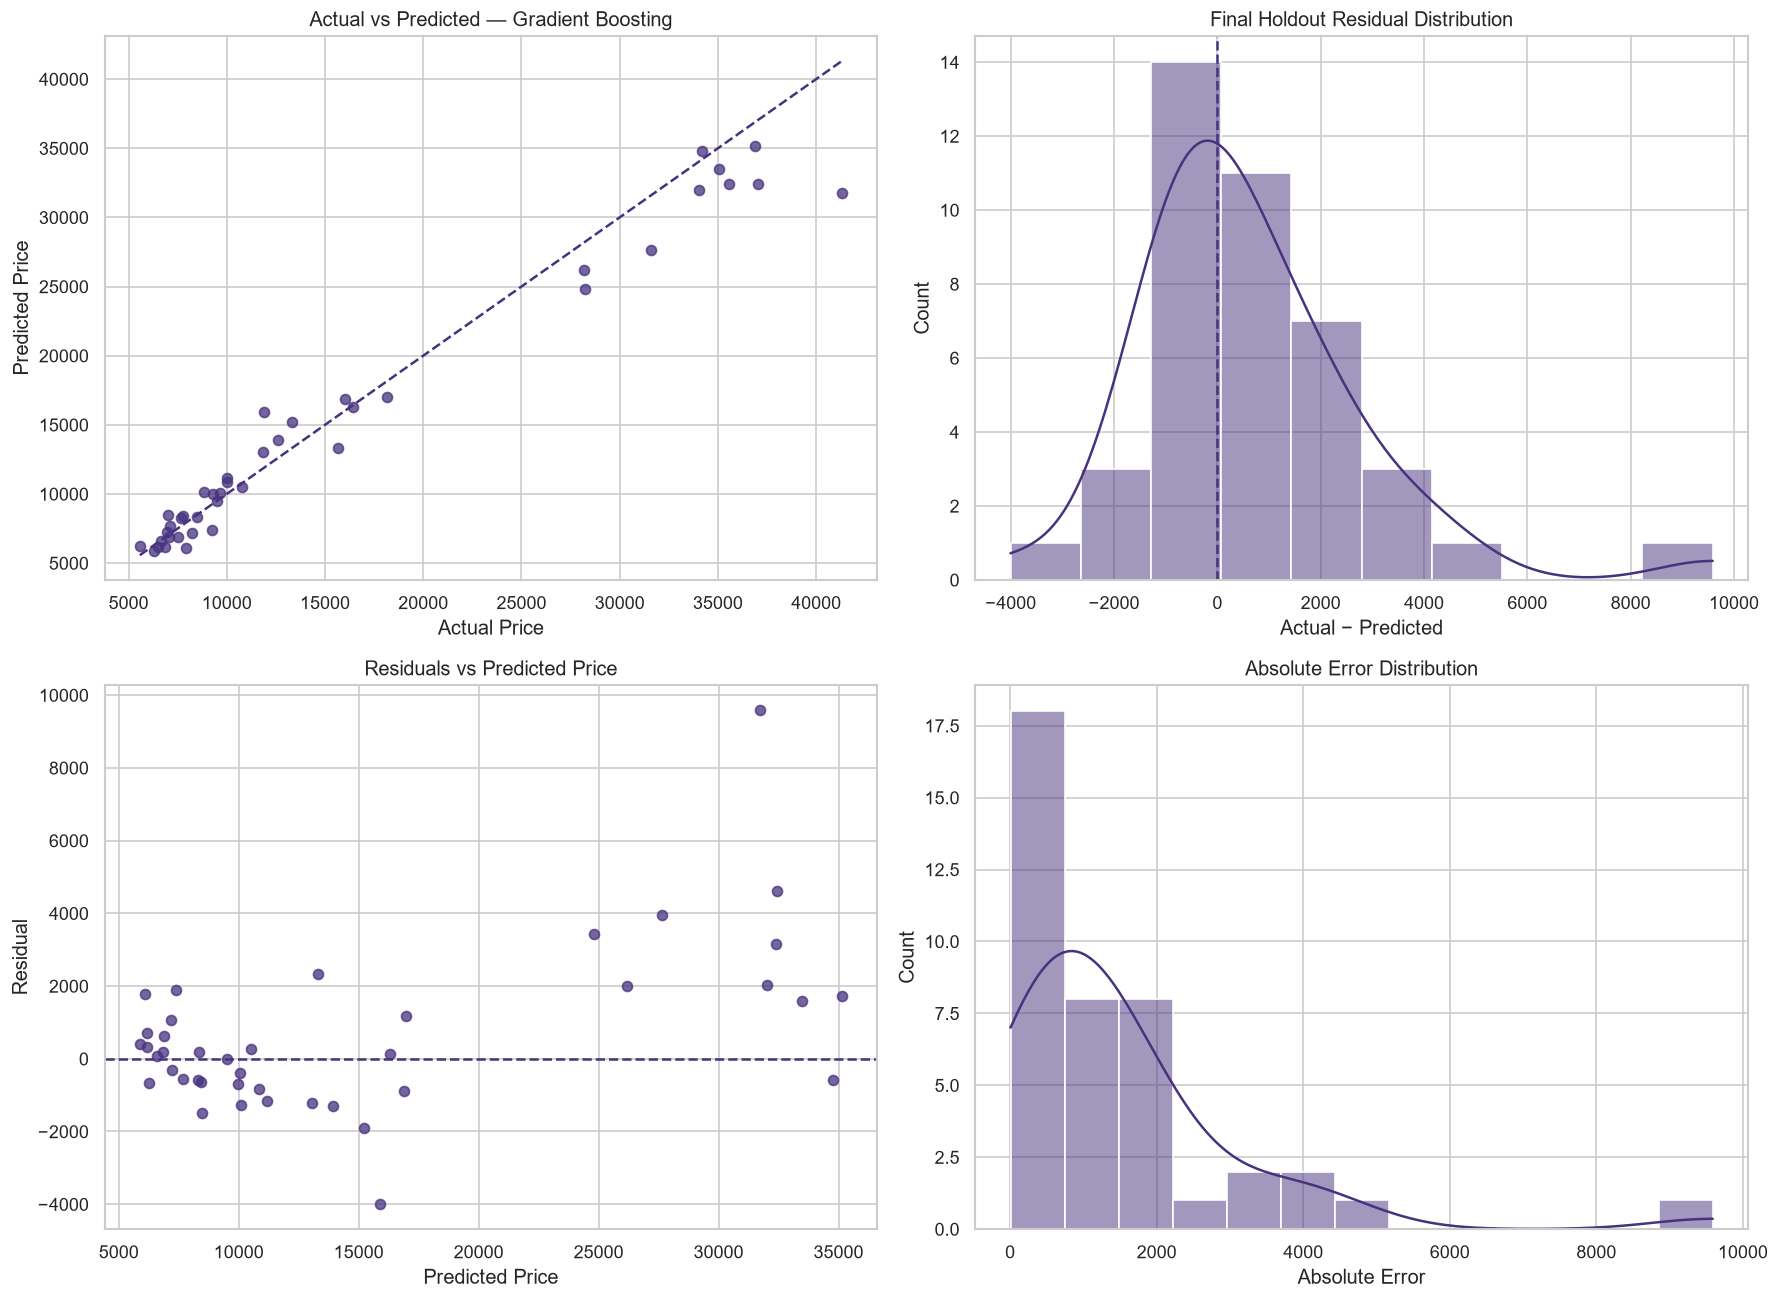

In [44]:
# Final diagnostic visualisations for the programmatically selected model.

residuals = y_test.to_numpy() - best_predictions

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

axes[0, 0].scatter(y_test, best_predictions, alpha=0.75)
min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())
axes[0, 0].plot([min_price, max_price], [min_price, max_price], linestyle="--")
axes[0, 0].set_title(f"Actual vs Predicted — {final_model_name}")
axes[0, 0].set_xlabel("Actual Price")
axes[0, 0].set_ylabel("Predicted Price")

sns.histplot(residuals, kde=True, ax=axes[0, 1])
axes[0, 1].axvline(0, linestyle="--")
axes[0, 1].set_title("Final Holdout Residual Distribution")
axes[0, 1].set_xlabel("Actual − Predicted")

axes[1, 0].scatter(best_predictions, residuals, alpha=0.75)
axes[1, 0].axhline(0, linestyle="--")
axes[1, 0].set_title("Residuals vs Predicted Price")
axes[1, 0].set_xlabel("Predicted Price")
axes[1, 0].set_ylabel("Residual")

sns.histplot(prediction_analysis["Absolute_Error"], kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Absolute Error Distribution")
axes[1, 1].set_xlabel("Absolute Error")

plt.tight_layout()
plt.savefig(
    VISUALIZATION_PATH / "07_final_model_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [45]:
# Final metrics for the selected model.

selected_cv_mae = float(best_tuning_row["Best_CV_MAE"])
final_model_metrics = {
    "Model": final_model_name,
    "Repeated_CV_MAE": selected_cv_mae,
    "Repeated_CV_MAE_Std": float(best_tuning_row["CV_MAE_Std"]),
    "Test_MAE": mean_absolute_error(y_test, best_predictions),
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, best_predictions)),
    "Test_R2": r2_score(y_test, best_predictions),
    "Test_MAPE_Percent": mean_absolute_percentage_error(y_test, best_predictions) * 100
}

final_model_summary = pd.DataFrame([final_model_metrics])
display(final_model_summary.round(3))

print(
    "MAE is the average absolute prediction error in the dataset's price units. "
    "RMSE penalises larger errors more strongly."
)
print(
    "MAPE is a relative percentage error and can become unstable when actual "
    "prices are close to zero."
)


,Model,Repeated_CV_MAE,Repeated_CV_MAE_Std,Test_MAE,Test_RMSE,Test_R2,Test_MAPE_Percent
0,Gradient Boosting,1535.229,215.056,1506.68,2275.749,0.958,9.552


MAE is the average absolute prediction error in the dataset's price units. RMSE penalises larger errors more strongly.
MAPE is a relative percentage error and can become unstable when actual prices are close to zero.


In [46]:
# Empirical bootstrap intervals for the final holdout metrics.
# These intervals resample the 41 holdout prediction pairs; with this small
# test sample they are approximate and should be interpreted cautiously.

rng = np.random.default_rng(42)
actual = y_test.to_numpy()
predicted = np.asarray(best_predictions)
bootstrap_rows = []

for _ in range(2000):
    sample_idx = rng.integers(0, len(actual), size=len(actual))
    actual_sample = actual[sample_idx]
    predicted_sample = predicted[sample_idx]

    row = {
        "MAE": mean_absolute_error(actual_sample, predicted_sample),
        "RMSE": np.sqrt(mean_squared_error(actual_sample, predicted_sample)),
        "MAPE_Percent": mean_absolute_percentage_error(
            actual_sample, predicted_sample
        ) * 100
    }
    if len(np.unique(actual_sample)) > 1:
        row["R2"] = r2_score(actual_sample, predicted_sample)
    else:
        row["R2"] = np.nan
    bootstrap_rows.append(row)

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_intervals = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "MAPE_Percent"],
    "Lower_95_CI": [
        bootstrap_df[c].quantile(0.025)
        for c in ["MAE", "RMSE", "R2", "MAPE_Percent"]
    ],
    "Upper_95_CI": [
        bootstrap_df[c].quantile(0.975)
        for c in ["MAE", "RMSE", "R2", "MAPE_Percent"]
    ]
})

display(bootstrap_intervals.round(3))
print(
    "Intervals describe empirical resampling variability in this small holdout "
    "sample; they are not a guarantee of future-market performance."
)


,Metric,Lower_95_CI,Upper_95_CI
0,MAE,1045.187,2111.269
1,RMSE,1378.171,3254.795
2,R2,0.925,0.981
3,MAPE_Percent,7.446,11.699


Intervals describe empirical resampling variability in this small holdout sample; they are not a guarantee of future-market performance.


In [47]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone

# Estimate permutation importance on validation folds from training data.
# The final test set is not used for feature selection or importance calculation.

fold_importances = []

for fold_number, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train), start=1):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_valid = X_train.iloc[valid_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    fold_model = clone(best_model)
    fold_model.fit(X_fold_train, y_fold_train)

    fold_result = permutation_importance(
        fold_model,
        X_fold_valid,
        y_fold_valid,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=42 + fold_number,
        n_jobs=-1
    )
    fold_importances.append(fold_result.importances_mean)

importance_matrix = np.vstack(fold_importances)

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance_Mean": importance_matrix.mean(axis=0),
    "Importance_Std": importance_matrix.std(axis=0, ddof=1)
}).sort_values("Importance_Mean", ascending=False).reset_index(drop=True)

display(feature_importance_df.round(3))
print("Importance is predictive association, not evidence of causation.")


,Feature,Importance_Mean,Importance_Std
0,curb_weight,1137.829,296.626
1,engine_size,410.982,308.996
2,horsepower,319.530,162.936
3,width,290.838,169.386
4,wheel_base,196.767,143.086
5,highway_mpg,194.874,139.192
6,make,132.988,122.138
7,city_mpg,125.805,101.162
8,length,64.919,52.306
9,body_style,39.709,45.384


Importance is predictive association, not evidence of causation.


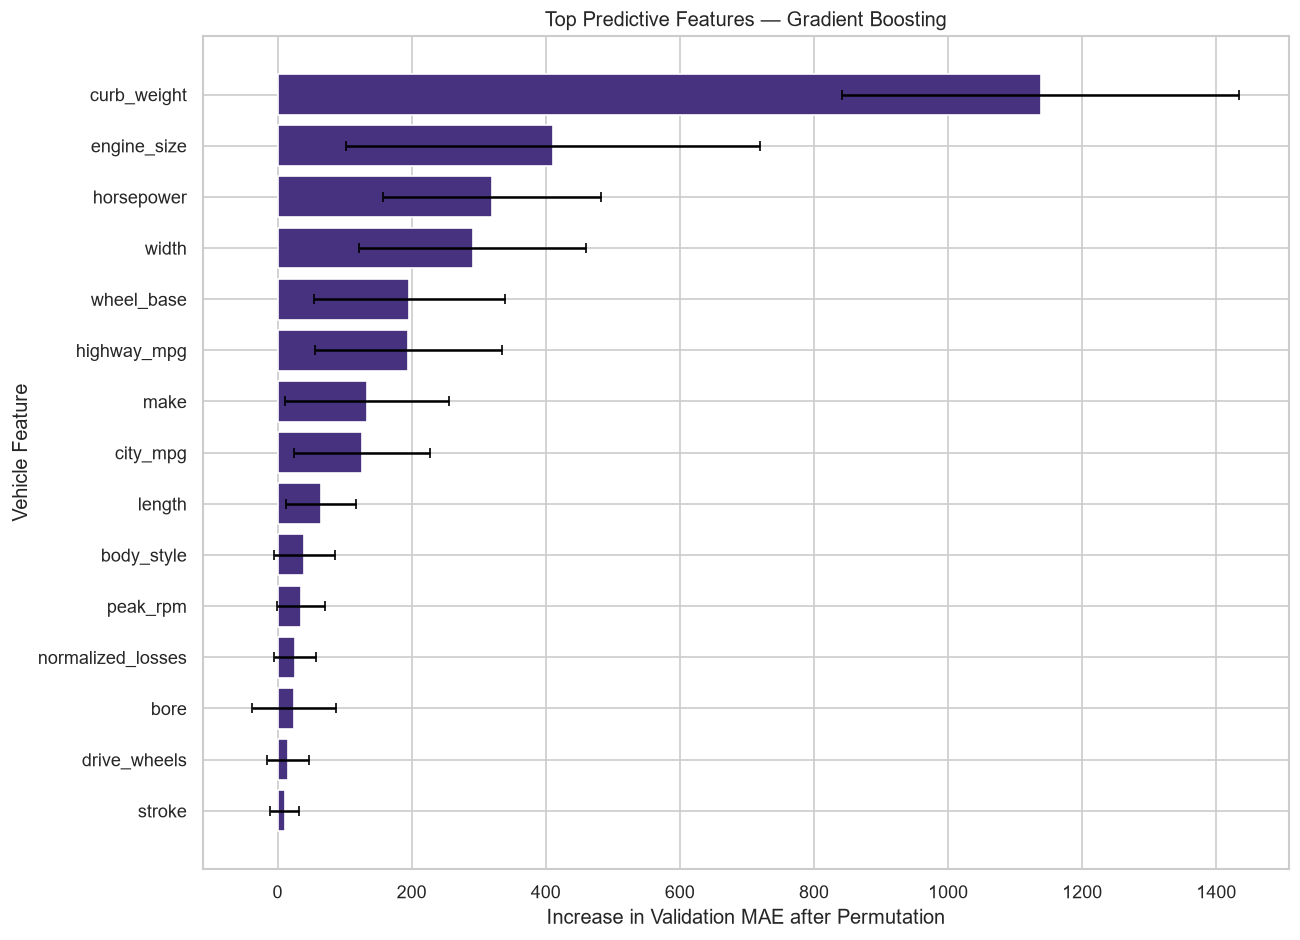

In [48]:
# Plot top features using cross-validated permutation importance.

top_features = feature_importance_df.head(15).sort_values(
    "Importance_Mean", ascending=True
)

plt.figure(figsize=(11, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"],
    capsize=3
)
plt.title(f"Top Predictive Features — {final_model_name}")
plt.xlabel("Increase in Validation MAE after Permutation")
plt.ylabel("Vehicle Feature")
plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "08_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 20. Model Persistence and Reusability

The selected trained model is saved using Joblib so that it can be reused without retraining.

The saved model is subsequently reloaded and tested to verify that its predictions remain consistent.

A reusable prediction function is developed to accept vehicle specifications, validate the supplied features and return a predicted automobile price.

In [49]:
print("MODEL_PATH:", MODEL_PATH.resolve())
print("Model already exists:", (MODEL_PATH / "automotive_price_prediction_model.joblib").exists())

MODEL_PATH: C:\Rakesh Project\Automotive-Evaluation-Improvements\models
Model already exists: False


In [50]:
import joblib

# Save the complete trained pipeline
final_model_path = MODEL_PATH / "automotive_price_prediction_model.joblib"

joblib.dump(best_model, final_model_path)

print("Final model saved successfully.")
print("Model path:", final_model_path)
print("File size:", round(final_model_path.stat().st_size / 1024, 2), "KB")

Final model saved successfully.
Model path: C:\Rakesh Project\Automotive-Evaluation-Improvements\models\automotive_price_prediction_model.joblib
File size: 192.82 KB


In [51]:
# Reload the saved model
loaded_model = joblib.load(final_model_path)

# Generate predictions using the reloaded model
loaded_predictions = loaded_model.predict(X_test)

# Verify predictions match the original model
predictions_match = np.allclose(
    best_predictions,
    loaded_predictions
)

print("Model reload successful:", loaded_model is not None)
print("Prediction consistency:", predictions_match)

print(
    "Reloaded model Test MAE:",
    round(mean_absolute_error(y_test, loaded_predictions), 2)
)

print(
    "Reloaded model Test R2:",
    round(r2_score(y_test, loaded_predictions), 4)
)

Model reload successful: True
Prediction consistency: True
Reloaded model Test MAE: 1506.68
Reloaded model Test R2: 0.9577


In [52]:
def predict_vehicle_price(vehicle_data, model=loaded_model):
    """
    Predict the price of a vehicle using the trained pipeline.

    Parameters:
        vehicle_data (dict): Vehicle specifications.
        model: Trained machine learning pipeline.

    Returns:
        float: Predicted vehicle price.
    """

    input_df = pd.DataFrame([vehicle_data])

    expected_columns = list(X_train.columns)

    missing_columns = set(expected_columns) - set(input_df.columns)
    extra_columns = set(input_df.columns) - set(expected_columns)

    if missing_columns or extra_columns:
        raise ValueError(
            f"Missing columns: {sorted(missing_columns)}. "
            f"Unexpected columns: {sorted(extra_columns)}."
        )

    input_df = input_df[expected_columns]

    predicted_price = model.predict(input_df)[0]

    return round(float(predicted_price), 2)


print("Prediction function created successfully.")

Prediction function created successfully.


In [53]:
# Select one vehicle from the original dataset
sample_vehicle = X.iloc[[0]].iloc[0].to_dict()

# Predict its price
sample_prediction = predict_vehicle_price(sample_vehicle)

print("Actual Vehicle Price:", y.iloc[0])
print("Predicted Vehicle Price:", sample_prediction)

Actual Vehicle Price: 13495
Predicted Vehicle Price: 15543.0


In [54]:
# Test with an intentionally incomplete vehicle record

invalid_vehicle = {
    "make": "toyota",
    "fuel_type": "gas"
}

try:
    predict_vehicle_price(invalid_vehicle)

except ValueError as error:
    print("Input validation successful.")
    print("Error:", error)

Input validation successful.
Error: Missing columns: ['aspiration', 'body_style', 'bore', 'city_mpg', 'compression_ratio', 'curb_weight', 'drive_wheels', 'engine_location', 'engine_size', 'engine_type', 'fuel_system', 'height', 'highway_mpg', 'horsepower', 'length', 'normalized_losses', 'num_of_cylinders', 'num_of_doors', 'peak_rpm', 'stroke', 'symboling', 'wheel_base', 'width']. Unexpected columns: [].


## 21. Production Prediction Module

The prediction functionality is organised into a separate Python module under the `src` directory.

The module supports model loading, input validation and vehicle price prediction.

Separating prediction functionality from the notebook makes the trained model easier to reuse in other Python applications.

In [56]:
predict_file = PROJECT_ROOT / "src" / "predict.py"

print("PROJECT_ROOT:", PROJECT_ROOT.resolve())
print("Prediction module:", predict_file.resolve())
print("File already exists:", predict_file.exists())
print("Source folder exists:", predict_file.parent.is_dir())

PROJECT_ROOT: C:\Rakesh Project\Automotive-Evaluation-Improvements
Prediction module: C:\Rakesh Project\Automotive-Evaluation-Improvements\src\predict.py
File already exists: False
Source folder exists: True


In [57]:
predict_file = PROJECT_ROOT / "src" / "predict.py"

predict_code = '''from pathlib import Path

import joblib
import pandas as pd


MODEL_PATH = (
    Path(__file__).resolve().parents[1]
    / "models"
    / "automotive_price_prediction_model.joblib"
)


def load_model():
    """Load the saved vehicle price prediction model."""
    if not MODEL_PATH.exists():
        raise FileNotFoundError(f"Model file not found: {MODEL_PATH}")

    return joblib.load(MODEL_PATH)


def predict_vehicle_price(vehicle_data, model=None):
    """
    Predict vehicle price from a dictionary or a single-row DataFrame.
    """

    if isinstance(vehicle_data, dict):
        input_df = pd.DataFrame([vehicle_data])
    elif isinstance(vehicle_data, pd.DataFrame):
        input_df = vehicle_data.copy()
    else:
        raise TypeError("Input must be a dictionary or pandas DataFrame.")

    if len(input_df) != 1:
        raise ValueError("Please provide exactly one vehicle record.")

    if model is None:
        model = load_model()

    expected_columns = list(model.feature_names_in_)

    missing_columns = set(expected_columns) - set(input_df.columns)
    extra_columns = set(input_df.columns) - set(expected_columns)

    if missing_columns or extra_columns:
        raise ValueError(
            f"Missing columns: {sorted(missing_columns)}. "
            f"Unexpected columns: {sorted(extra_columns)}."
        )

    input_df = input_df[expected_columns]

    predicted_price = float(model.predict(input_df)[0])

    return round(predicted_price, 2)
'''

predict_file.write_text(predict_code, encoding="utf-8")

print("Prediction module created:", predict_file)
print("File exists:", predict_file.exists())

Prediction module created: C:\Rakesh Project\Automotive-Evaluation-Improvements\src\predict.py
File exists: True


In [58]:
import sys

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from predict import predict_vehicle_price as production_predict

# Predict using the production module
production_prediction = production_predict(sample_vehicle)

print("Notebook prediction:", sample_prediction)
print("Production module prediction:", production_prediction)
print(
    "Predictions match:",
    np.isclose(sample_prediction, production_prediction)
)

Notebook prediction: 15543.0
Production module prediction: 15543.0
Predictions match: True


## 22. Automated Testing

Pytest is used to validate the reusable prediction module.

The test suite checks:

- Successful predictions using valid vehicle features.
- Error handling when required features are missing.
- Error handling when the supplied input has an invalid data type.

All three tests passed during project verification.

In [59]:
test_file = PROJECT_ROOT / "tests" / "test_prediction.py"

print("Test file:", test_file.resolve())
print("File already exists:", test_file.exists())
print("Tests folder exists:", test_file.parent.is_dir())

Test file: C:\Rakesh Project\Automotive-Evaluation-Improvements\tests\test_prediction.py
File already exists: False
Tests folder exists: True


In [60]:
test_file = PROJECT_ROOT / "tests" / "test_prediction.py"

test_code = '''import sys
from pathlib import Path

import pytest

PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from predict import predict_vehicle_price


def get_valid_vehicle():
    return {
        "symboling": 3,
        "normalized_losses": 122,
        "make": "alfa-romero",
        "fuel_type": "gas",
        "aspiration": "std",
        "num_of_doors": "two",
        "body_style": "convertible",
        "drive_wheels": "rwd",
        "engine_location": "front",
        "wheel_base": 88.6,
        "length": 168.8,
        "width": 64.1,
        "height": 48.8,
        "curb_weight": 2548,
        "engine_type": "dohc",
        "num_of_cylinders": "four",
        "engine_size": 130,
        "fuel_system": "mpfi",
        "bore": 3.47,
        "stroke": 2.68,
        "compression_ratio": 9.0,
        "horsepower": 111,
        "peak_rpm": 5000,
        "city_mpg": 21,
        "highway_mpg": 27
    }


def test_valid_vehicle_prediction():
    prediction = predict_vehicle_price(get_valid_vehicle())

    assert isinstance(prediction, float)
    assert prediction > 0


def test_missing_features_raise_error():
    invalid_vehicle = {
        "make": "toyota",
        "fuel_type": "gas"
    }

    with pytest.raises(ValueError, match="Missing columns"):
        predict_vehicle_price(invalid_vehicle)


def test_invalid_input_type_raises_error():
    with pytest.raises(TypeError):
        predict_vehicle_price("invalid input")
'''

test_file.write_text(test_code, encoding="utf-8")

print("Test file created:", test_file)
print("File exists:", test_file.exists())

Test file created: C:\Rakesh Project\Automotive-Evaluation-Improvements\tests\test_prediction.py
File exists: True


In [61]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pytest", str(PROJECT_ROOT / "tests"), "-q"],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

...                                                                      [100%]
3 passed in 1.95s


Exit code: 0


In [62]:
import subprocess
import sys

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        str(PROJECT_ROOT / "tests" / "test_prediction.py"),
        "-v"
    ],
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr:
    print(test_result.stderr)

print("Pytest exit code:", test_result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.13.17, pytest-9.2.0, pluggy-1.7.0 -- C:\Rakesh Project\Automotive-Price-Intelligence\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Rakesh Project
plugins: anyio-4.16.0, platformdirs-4.14.5
collecting ... collected 3 items

..\..\Automotive-Evaluation-Improvements\tests\test_prediction.py::test_valid_vehicle_prediction PASSED [ 33%]
..\..\Automotive-Evaluation-Improvements\tests\test_prediction.py::test_missing_features_raise_error PASSED [ 66%]
..\..\Automotive-Evaluation-Improvements\tests\test_prediction.py::test_invalid_input_type_raises_error PASSED [100%]

============================== 3 passed in 2.31s ==============================

Pytest exit code: 0


In [63]:
chart_file = VISUALIZATION_PATH / "09_price_by_engine_type.png"

print("Chart destination:", chart_file.resolve())
print("Chart already exists:", chart_file.exists())
print("Visualization folder exists:", chart_file.parent.is_dir())

Chart destination: C:\Rakesh Project\Automotive-Evaluation-Improvements\visualizations\09_price_by_engine_type.png
Chart already exists: False
Visualization folder exists: True


,Count,Median_Price,Mean_Price
engine_type,,,
ohcv,13,19699.0,25098.38
dohc,12,16249.0,18116.42
l,12,16105.0,14627.58
rotor,4,12745.0,13020.00
ohcf,15,9233.0,13738.60
ohc,145,9095.0,11567.36


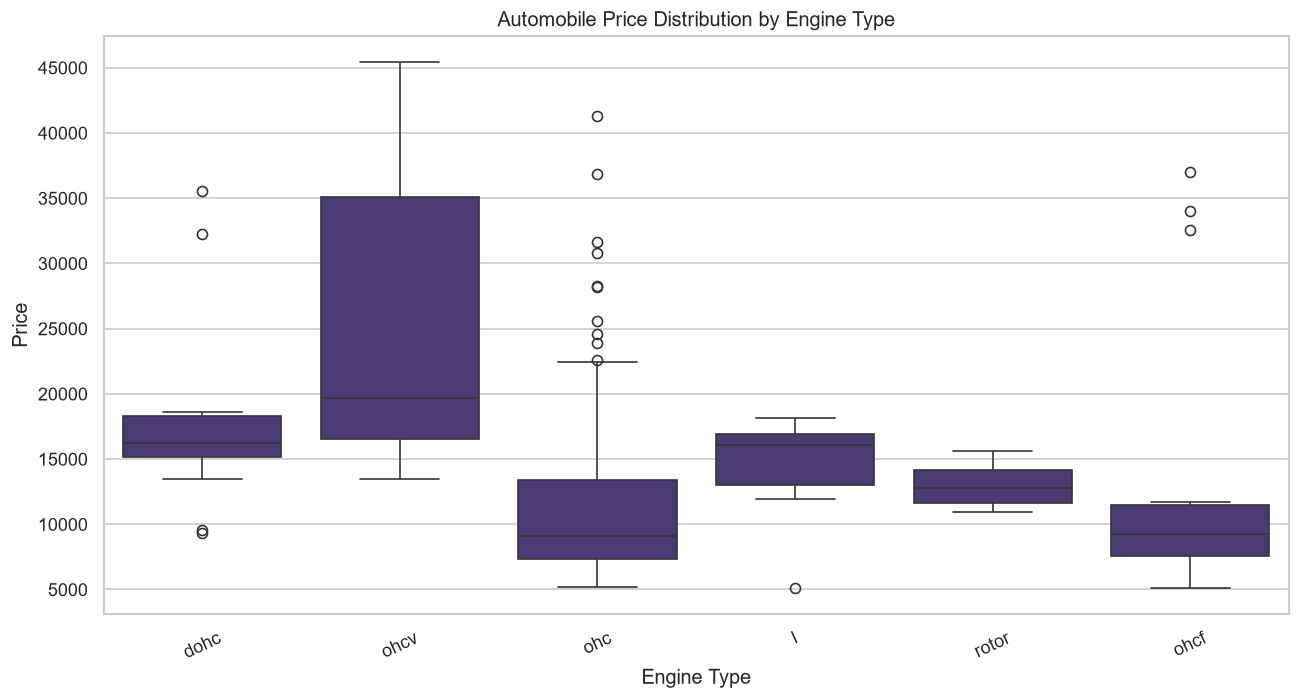

Interpret category medians alongside group counts. Small groups can have unstable medians and should not be treated as statistically conclusive.


In [64]:
# Price distribution by engine type (replaces the duplicate overall price histogram).

engine_price_summary = (
    df.groupby("engine_type")["price"]
    .agg(Count="count", Median_Price="median", Mean_Price="mean")
    .sort_values("Median_Price", ascending=False)
)

display(engine_price_summary.round(2))

plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x="engine_type", y="price")
plt.title("Automobile Price Distribution by Engine Type")
plt.xlabel("Engine Type")
plt.ylabel("Price")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(
    VISUALIZATION_PATH / "09_price_by_engine_type.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(
    "Interpret category medians alongside group counts. Small groups can have "
    "unstable medians and should not be treated as statistically conclusive."
)


## 23. Supporting Reports and Project Documentation

Additional project deliverables are generated to document the modelling process and support project reproducibility.

These include:

- Model Comparison Report.
- Challenges Faced Report.
- Requirements file.
- Git ignore configuration.
- Project README.

The supporting documentation summarises the project methodology, model performance, challenges, limitations and recommended model.

In [65]:
model_report_path = REPORT_PATH / "model_comparison_report.md"

print("Report destination:", model_report_path.resolve())
print("Report already exists:", model_report_path.exists())
print("Reports folder exists:", model_report_path.parent.is_dir())

Report destination: C:\Rakesh Project\Automotive-Evaluation-Improvements\reports\model_comparison_report.md
Report already exists: False
Reports folder exists: True


In [66]:
# Generate the model comparison report from the current notebook results.

selected_params = best_model.named_steps["regressor"].get_params()
params_text = "\n".join(
    f"- {name}: {selected_params[name]}"
    for name in [
        "learning_rate", "n_estimators", "max_depth",
        "min_samples_leaf", "subsample"
    ]
)

model_report = f"""# Automotive Price Intelligence & Prediction
## Model Comparison Report — Evaluation Improvements

### Evaluation Design
- Dataset records: {len(df)}
- Training records: {len(X_train)}
- Independent holdout records: {len(X_test)}
- Model-selection method: repeated 5-fold cross-validation (2 repeats)
- Hyperparameter search: 8 sampled configurations per tuned model
- The holdout set was used only once, after model selection.

### Selected Model
**{final_model_name}**

Selected using the lowest repeated-CV MAE among the tuned candidates.

### Final Performance

| Metric | Result |
|---|---:|
| Repeated-CV MAE | {final_model_metrics['Repeated_CV_MAE']:.2f} |
| Repeated-CV MAE standard deviation | {final_model_metrics['Repeated_CV_MAE_Std']:.2f} |
| Holdout MAE | {final_model_metrics['Test_MAE']:.2f} |
| Holdout RMSE | {final_model_metrics['Test_RMSE']:.2f} |
| Holdout R² | {final_model_metrics['Test_R2']:.4f} |
| Holdout MAPE | {final_model_metrics['Test_MAPE_Percent']:.2f}% |

### Bootstrap Intervals
The empirical 95% bootstrap intervals are reported in the notebook. They are based on resampling the small holdout set and should be interpreted cautiously.

### Selected Estimator Parameters
{params_text}

### Metric Interpretation
MAE is the average absolute prediction error in the dataset's price units. RMSE gives larger errors greater influence. MAPE expresses average relative error but can be unstable for observations with very small actual prices.

### Limitations
The dataset contains only {len(df)} historical records. It represents an older automobile-import market and does not establish accuracy for current vehicle prices. Feature importance describes predictive association, not causation. External validation on a larger, current dataset is required before operational use.
"""

model_report_path = REPORT_PATH / "model_comparison_report.md"
model_report_path.write_text(model_report, encoding="utf-8")
print("Updated model comparison report:", model_report_path)


Updated model comparison report: C:\Rakesh Project\Automotive-Evaluation-Improvements\reports\model_comparison_report.md


In [67]:
challenges_report_path = REPORT_PATH / "challenges_faced_report.md"

print("Report destination:", challenges_report_path.resolve())
print("Report already exists:", challenges_report_path.exists())
print("Reports folder exists:", challenges_report_path.parent.is_dir())

Report destination: C:\Rakesh Project\Automotive-Evaluation-Improvements\reports\challenges_faced_report.md
Report already exists: False
Reports folder exists: True


In [68]:
# Generate a current challenges and methodology report.

challenges_report = f"""# Automotive Price Intelligence & Prediction
## Challenges Faced and Methodology Improvements

### Dataset Size and Scope
The supplied dataset contains {len(df)} records and represents historical automobile imports. Small samples limit the precision and generalisability of model estimates.

### Missing Data
Missing feature values are handled inside the model pipeline: median imputation for numerical columns and most-frequent imputation for categorical columns. The imputer is fitted separately within each training fold.

### Mixed Feature Types
A ColumnTransformer applies numerical scaling and categorical one-hot encoding. Unknown categories are handled without failing prediction.

### Outliers and Skew
Potential outliers are identified with the IQR rule and reviewed rather than automatically deleted. IQR flags unusual observations; it does not prove that a record is erroneous.

### Leakage Prevention
The preprocessor is not fitted before cross-validation. Each pipeline fits preprocessing only on the training portion of each fold. The independent holdout is not used for model selection or permutation importance.

### Model Selection and Validation
Candidate models and tuned parameters are compared using repeated 5-fold cross-validation on the training data. The selected model is chosen programmatically using the lowest repeated-CV MAE. Only that selected model is evaluated on the independent holdout.

### Uncertainty
Bootstrap intervals are calculated from the final holdout predictions. With only {len(X_test)} holdout records, these intervals are approximate and may be unstable.

### Feature Importance
Permutation importance is calculated on training-data validation folds. It measures predictive dependence, not causal impact. Correlated features may share or mask importance.

### Operational Limitations
The selected model is a learning and demonstration prototype. It should not be deployed for current commercial pricing without current market data, external validation, uncertainty analysis, monitoring and fairness review.
"""

challenges_report_path = REPORT_PATH / "challenges_faced_report.md"
challenges_report_path.write_text(challenges_report, encoding="utf-8")
print("Updated challenges report:", challenges_report_path)


Updated challenges report: C:\Rakesh Project\Automotive-Evaluation-Improvements\reports\challenges_faced_report.md


In [69]:
from importlib.metadata import version, PackageNotFoundError

packages = [
    "pandas", "numpy", "matplotlib", "seaborn",
    "scikit-learn", "scipy", "statsmodels",
    "joblib", "pytest", "jupyter", "ipykernel"
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1
scipy: 1.18.1
statsmodels: 0.15.0
joblib: 1.6.0
pytest: 9.2.0
jupyter: 1.1.1
ipykernel: 7.4.0


In [70]:
requirements_path = PROJECT_ROOT / "requirements.txt"

print("Destination:", requirements_path.resolve())
print("File already exists:", requirements_path.exists())
print("Project folder exists:", requirements_path.parent.is_dir())

Destination: C:\Rakesh Project\Automotive-Evaluation-Improvements\requirements.txt
File already exists: False
Project folder exists: True


In [71]:
requirements = """pandas==3.1.1
numpy==2.5.4
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
scipy==1.18.1
statsmodels==0.15.0
joblib==1.6.0
pytest==9.2.0
jupyter==1.1.1
ipykernel==7.4.0
"""

requirements_path = PROJECT_ROOT / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print("Requirements file created:", requirements_path)
print("File exists:", requirements_path.exists())

Requirements file created: C:\Rakesh Project\Automotive-Evaluation-Improvements\requirements.txt
File exists: True


In [72]:
from pathlib import Path

print("gitignore_path defined:", "gitignore_path" in globals())

if "gitignore_path" in globals():
    print("Destination:", gitignore_path.resolve())
    print("File already exists:", gitignore_path.exists())
else:
    print("Expected destination:", (PROJECT_ROOT / ".gitignore").resolve())
    print("File already exists:", (PROJECT_ROOT / ".gitignore").exists())
    

gitignore_path defined: False
Expected destination: C:\Rakesh Project\Automotive-Evaluation-Improvements\.gitignore
File already exists: False


In [73]:
gitignore_path = PROJECT_ROOT / ".gitignore"
gitignore_content = """# Virtual environments
.venv/
venv/
env/

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Testing and coverage
.pytest_cache/
.coverage
htmlcov/

# Local environment and secrets
.env
.env.*

# Operating system files
.DS_Store
Thumbs.db
"""

gitignore_path.write_text(gitignore_content, encoding="utf-8")

print("Updated .gitignore successfully.")
print(gitignore_path.read_text(encoding="utf-8"))

Updated .gitignore successfully.
# Virtual environments
.venv/
venv/
env/

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Testing and coverage
.pytest_cache/
.coverage
htmlcov/

# Local environment and secrets
.env
.env.*

# Operating system files
.DS_Store
Thumbs.db



## 24. Project README

The README provides an overview of the project, its objectives, dataset, technologies, machine learning approach, model performance and project structure.

It also explains how to install the dependencies, execute the notebook, use the prediction module and run the automated tests.

In [74]:
readme_path = PROJECT_ROOT / "README.md"

print("README file already exists:", readme_path.exists())

README file already exists: False


In [75]:
readme_content = """# Automotive Price Intelligence & Prediction

## Project Overview

Automotive Price Intelligence & Prediction is a machine learning project developed to analyse automobile characteristics and predict vehicle prices using historical automobile import data.

The project explores the relationship between vehicle specifications and pricing, compares multiple regression algorithms, and identifies a suitable predictive model.

"""

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("Project title and overview added successfully.")

Project title and overview added successfully.


In [76]:
objectives = """## Project Objectives

- Perform exploratory data analysis on automobile specifications.
- Identify important factors associated with vehicle prices.
- Handle missing values and prepare numerical and categorical features.
- Train and compare multiple regression algorithms.
- Optimise model hyperparameters using cross-validation.
- Evaluate model performance on an independent test dataset.
- Develop a reusable prediction module.
- Document modelling challenges and business insights.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(objectives)

print("Project objectives added successfully.")

Project objectives added successfully.


In [77]:
dataset_section = """## Dataset

- Source: 1985 Auto Imports Database.
- Records supplied: 201.
- Attributes: 26.
- Independent variables: 25.
- Target variable: `price`.

The supplied dataset contains missing values in several independent variables. No target prices were missing.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(dataset_section)

print("Dataset information added successfully.")

Dataset information added successfully.


In [78]:
technology_section = """## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- SciPy
- Statsmodels
- Joblib
- Jupyter Notebook
- Pytest

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(technology_section)

print("Technologies section added successfully.")

Technologies section added successfully.


In [79]:
models_section = """## Machine Learning Models

The following regression algorithms were evaluated:

1. Dummy Regressor (baseline)
2. Linear Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Random Forest Regressor
7. Extra Trees Regressor
8. Gradient Boosting Regressor

Hyperparameter optimisation was performed using RandomizedSearchCV with five-fold cross-validation.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(models_section)

print("Machine learning models section added successfully.")

Machine learning models section added successfully.


In [80]:
performance_section = f"""## Final Model Performance

The final model was selected programmatically using repeated cross-validation on training data. The independent holdout set was evaluated only after selection.

| Metric | Result |
|---|---:|
| Selected model | {final_model_name} |
| Repeated-CV MAE | {final_model_metrics['Repeated_CV_MAE']:.2f} |
| Holdout MAE | {final_model_metrics['Test_MAE']:.2f} |
| Holdout RMSE | {final_model_metrics['Test_RMSE']:.2f} |
| Holdout R² | {final_model_metrics['Test_R2']:.4f} |
| Holdout MAPE | {final_model_metrics['Test_MAPE_Percent']:.2f}% |

The holdout contains {len(X_test)} records. See the model comparison report and notebook for bootstrap intervals and limitations.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(performance_section)

print("Dynamic final model performance section added.")


Dynamic final model performance section added.


In [81]:
findings_section = "## Key Findings\n\n"
for row in feature_importance_df.head(5).itertuples(index=False):
    findings_section += f"- {row.Feature}: mean validation permutation importance {row.Importance_Mean:.2f}\n"
findings_section += ("\nThese are predictive associations, not causal effects. "
                     "Importance estimates can be unstable for correlated features and small folds.\n\n")
with open(readme_path, "a", encoding="utf-8") as file:
    file.write(findings_section)
print("Data-driven findings section added.")


Data-driven findings section added.


In [82]:
structure_section = """## Project Structure

Automotive-Evaluation-Improvements/
|
|-- data/
|   |-- raw/
|   |-- processed/
|
|-- notebooks/
|   |-- Automotive_Price_Intelligence_and_Prediction.ipynb
|
|-- src/
|   |-- predict.py
|
|-- models/
|   |-- automotive_price_prediction_model.joblib
|
|-- visualizations/
|
|-- reports/
|   |-- model_comparison_report.md
|   |-- challenges_faced_report.md
|
|-- tests/
|   |-- test_prediction.py
|
|-- documentation/
|
|-- requirements.txt
|-- .gitignore
|-- README.md

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(structure_section)

print("Project structure section added successfully.")

Project structure section added successfully.


In [83]:
installation_section = """## Installation

Clone the repository and navigate to the project directory.

Create a virtual environment:

    python -m venv .venv

Activate the environment in Windows PowerShell:

    .venv\\Scripts\\Activate.ps1

Install the required dependencies:

    pip install -r requirements.txt

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(installation_section)

print("Installation instructions added successfully.")

Installation instructions added successfully.


In [85]:
notebook_section = """## Running the Notebook

Start Jupyter Notebook:

    jupyter notebook

Open the following notebook:

    notebooks/Automotive_Price_Intelligence_Improved_Copy.ipynb

Select the appropriate Python environment and execute the notebook cells in order.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(notebook_section)

print("Notebook instructions added successfully.")

Notebook instructions added successfully.


In [86]:
from pathlib import Path

prediction_file = PROJECT_ROOT / "src" / "predict.py"
print(prediction_file.read_text(encoding="utf-8"))

from pathlib import Path

import joblib
import pandas as pd


MODEL_PATH = (
    Path(__file__).resolve().parents[1]
    / "models"
    / "automotive_price_prediction_model.joblib"
)


def load_model():
    """Load the saved vehicle price prediction model."""
    if not MODEL_PATH.exists():
        raise FileNotFoundError(f"Model file not found: {MODEL_PATH}")

    return joblib.load(MODEL_PATH)


def predict_vehicle_price(vehicle_data, model=None):
    """
    Predict vehicle price from a dictionary or a single-row DataFrame.
    """

    if isinstance(vehicle_data, dict):
        input_df = pd.DataFrame([vehicle_data])
    elif isinstance(vehicle_data, pd.DataFrame):
        input_df = vehicle_data.copy()
    else:
        raise TypeError("Input must be a dictionary or pandas DataFrame.")

    if len(input_df) != 1:
        raise ValueError("Please provide exactly one vehicle record.")

    if model is None:
        model = load_model()

    expected_columns = list(model.feature_name

In [87]:

prediction_section = """## Making a Prediction

The reusable prediction module is located at `src/predict.py`.

Example usage (run from the project root):

    from src.predict import predict_vehicle_price

    vehicle = {
        # Replace with all 25 required feature names and values.
    }

    predicted_price = predict_vehicle_price(vehicle)
    print(predicted_price)

The function accepts a dictionary or single-row pandas DataFrame,
validates all required feature names, loads the saved model,
and returns the predicted price.

See the notebook for a complete vehicle input example.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(prediction_section)

print("Prediction instructions added successfully.")


Prediction instructions added successfully.


In [88]:
testing_section = """## Automated Testing

Run the tests from the project root:

    python -m pytest tests/ -v

The current test suite covers:

- Valid vehicle predictions.
- Missing feature validation.
- Invalid input type validation.

All three tests passed during project verification.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(testing_section)

print("Automated testing section added successfully.")

Automated testing section added successfully.


In [89]:
reports_section = """## Reports and Visualisations

The reports directory contains:

- Model Comparison Report.
- Challenges Faced Report.

The visualizations directory contains exploratory data analysis plots, feature importance analysis and final model diagnostic plots.

These visualisations cover:

- Correlation analysis.
- Manufacturer distribution.
- Categorical feature analysis against price.
- Numerical feature distributions.
- Missing value analysis.
- Numerical features against price.
- Final model diagnostics.
- Feature importance.
- Automobile price distribution.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(reports_section)

print("Reports and visualisations section added successfully.")

Reports and visualisations section added successfully.


In [90]:
limitations_section = """## Limitations

- The dataset is small, containing only 201 supplied records.
- It represents historical automobile imports from the 1980s.
- The independent test set contains only 41 records.
- Results do not establish prediction accuracy for modern automobile markets.
- External validation using larger and more recent datasets is recommended before commercial deployment.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(limitations_section)

print("Project limitations section added successfully.")

Project limitations section added successfully.


In [91]:
conclusion_section = f"""## Conclusion

The model selected using training-only repeated cross-validation was **{final_model_name}**.

On the independent holdout set of {len(X_test)} records:
- MAE: {final_model_metrics['Test_MAE']:.2f} dataset price units
- RMSE: {final_model_metrics['Test_RMSE']:.2f} dataset price units
- R²: {final_model_metrics['Test_R2']:.4f}
- MAPE: {final_model_metrics['Test_MAPE_Percent']:.2f}%

This historical, small-sample model is a demonstration prototype, not a current-market commercial pricing tool. It requires recent representative data, external validation, monitoring and fairness assessment before deployment.
"""
with open(readme_path, "a", encoding="utf-8") as file:
    file.write(conclusion_section)
print("Data-driven conclusion section added.")


Data-driven conclusion section added.


In [92]:
readme_content = readme_path.read_text(encoding="utf-8")

readme_content = readme_content.replace(
    "from predict import predict_vehicle_price",
    "from src.predict import predict_vehicle_price"
)

readme_path.write_text(readme_content, encoding="utf-8")

print("Prediction import instruction corrected.")
print(
    "Correct import present:",
    "from src.predict import predict_vehicle_price"
    in readme_path.read_text(encoding="utf-8")
)

Prediction import instruction corrected.
Correct import present: True


In [93]:
readme_content = readme_path.read_text(encoding="utf-8")

required_sections = [
    "## Project Overview",
    "## Project Objectives",
    "## Dataset",
    "## Technologies Used",
    "## Machine Learning Models",
    "## Final Model Performance",
    "## Key Findings",
    "## Project Structure",
    "## Installation",
    "## Running the Notebook",
    "## Making a Prediction",
    "## Automated Testing",
    "## Reports and Visualisations",
    "## Limitations",
    "## Conclusion"
]

missing_sections = [
    section for section in required_sections
    if section not in readme_content
]

print("README exists:", readme_path.exists())
print("README size:", round(readme_path.stat().st_size / 1024, 2), "KB")
print("Total sections:", len(required_sections))
print("Missing sections:", missing_sections)
print(
    "Correct prediction import:",
    "from src.predict import predict_vehicle_price" in readme_content
)

README exists: True
README size: 6.28 KB
Total sections: 15
Missing sections: []
Correct prediction import: True


In [ ]:
from pathlib import Path
readme_path = PROJECT_ROOT / 'README.md'
text = readme_path.read_text(encoding='utf-8')
start = text.index('## Project Structure')
end = text.index('## Installation', start)
structure = [
    '## Project Structure',
    '',
    'Automotive-Evaluation-Improvements/',
    '- data/raw/auto_imports.csv',
    '- notebooks/Automotive_Price_Intelligence_Improved_Copy.ipynb',
    '- src/predict.py',
    '- models/automotive_price_prediction_model.joblib',
    '- visualizations/ (9 charts)',
    '- reports/model_comparison_report.md',
    '- reports/challenges_faced_report.md',
    '- tests/test_prediction.py',
    '- requirements.txt',
    '- .gitignore',
    '- README.md',
    '',
]
text = text[:start] + '\n'.join(structure) + '\n' + text[end:]
text = text.replace('- Automobile price distribution.', '- Vehicle price by engine type.')
import re
text = re.sub(
    r'Hyperparameter tuning and model selection use the same cross-validation framework\..*?final performance assessment\.\s*',
    '', text, flags=re.DOTALL
)
text = re.sub(
    r'Hyperparameter tuning and model selection use the same cross-validation framework\..*?final performance assessment\.\s*',
    '', text, flags=re.DOTALL
)
limitation = (
    'Hyperparameter tuning and model selection use the same cross-validation framework. '
    'The best CV estimate may therefore be optimistic. The independent holdout '
    'provides a separate final performance assessment.'
)
text = text.replace('## Key Findings', limitation + '\n\n## Key Findings', 1)

start = text.index('## Making a Prediction')
end = text.index('## Automated Testing', start)
prediction = [
    '## Making a Prediction',
    '',
    'Run this Python example from the project root:',
    '',
    '```python',
    'from src.predict import predict_vehicle_price',
    'from tests.test_prediction import get_valid_vehicle',
    'vehicle = get_valid_vehicle()',
    'predicted_price = predict_vehicle_price(vehicle)',
    "print(f'Predicted vehicle price: {predicted_price:.2f}')",
    '```',
    '',
]
text = text[:start] + '\n'.join(prediction) + '\n' + text[end:]
readme_path.write_text(text, encoding='utf-8')
print('README corrections applied after generation.')

In [94]:
from importlib import metadata

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "statsmodels",
    "joblib",
    "pytest",
    "jupyter",
    "ipykernel"
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1
scipy: 1.18.1
statsmodels: 0.15.0
joblib: 1.6.0
pytest: 9.2.0
jupyter: 1.1.1
ipykernel: 7.4.0


## Use of AI Tools

AI tools, including ChatGPT, were used as supporting resources during project development to help understand machine learning concepts, troubleshoot errors, review code, improve documentation, and refine the project workflow.

The project involved hands-on implementation, execution, testing, and verification. AI assistance supported the learning and problem-solving process, while project decisions and final results were reviewed during development.

## Final Project Conclusion

The following cell generates a concise conclusion from the results produced by this run. It distinguishes model performance on this historical sample from readiness for real-world deployment.

In [95]:
print("FINAL PROJECT CONCLUSION")
print("=" * 72)
print(f"Selected model: {final_model_name}")
print(f"Repeated-CV MAE: {final_model_metrics['Repeated_CV_MAE']:.2f} price units")
print(f"Holdout MAE: {final_model_metrics['Test_MAE']:.2f} price units")
print(f"Holdout RMSE: {final_model_metrics['Test_RMSE']:.2f} price units")
print(f"Holdout R²: {final_model_metrics['Test_R2']:.4f}")
print(f"Holdout MAPE: {final_model_metrics['Test_MAPE_Percent']:.2f}%")
print("\nInterpretation:")
print(
    f"On the {len(X_test)}-record holdout sample, the selected model's average "
    f"absolute prediction error was {final_model_metrics['Test_MAE']:.2f} "
    "in the dataset's price units."
)
print(
    "The model is a historical-data prototype, not a validated current-market "
    "pricing system. The dataset is small and old; external validation with "
    "recent, representative vehicle data is required before operational use."
)
print(
    "Feature importance indicates predictive association, not causation. "
    "Bootstrap intervals are approximate because the holdout sample is small."
)
print("\nGenerated deliverables are isolated under:", PROJECT_ROOT)


FINAL PROJECT CONCLUSION
Selected model: Gradient Boosting
Repeated-CV MAE: 1535.23 price units
Holdout MAE: 1506.68 price units
Holdout RMSE: 2275.75 price units
Holdout R²: 0.9577
Holdout MAPE: 9.55%

Interpretation:
On the 41-record holdout sample, the selected model's average absolute prediction error was 1506.68 in the dataset's price units.
The model is a historical-data prototype, not a validated current-market pricing system. The dataset is small and old; external validation with recent, representative vehicle data is required before operational use.
Feature importance indicates predictive association, not causation. Bootstrap intervals are approximate because the holdout sample is small.

Generated deliverables are isolated under: C:\Rakesh Project\Automotive-Evaluation-Improvements


In [96]:
from pathlib import Path

for path in sorted(PROJECT_ROOT.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))

.gitignore
.pytest_cache\.gitignore
.pytest_cache\CACHEDIR.TAG
.pytest_cache\README.md
.pytest_cache\v\cache\nodeids
models\automotive_price_prediction_model.joblib
README.md
reports\challenges_faced_report.md
reports\model_comparison_report.md
requirements.txt
src\__pycache__\predict.cpython-313.pyc
src\predict.py
tests\__pycache__\test_prediction.cpython-313-pytest-9.2.0.pyc
tests\test_prediction.py
visualizations\01_correlation_matrix.png
visualizations\02_manufacturer_distribution.png
visualizations\03_categorical_price_analysis.png
visualizations\04_numerical_distributions.png
visualizations\05_missing_values_analysis.png
visualizations\06_numerical_features_vs_price.png
visualizations\07_final_model_diagnostics.png
visualizations\08_feature_importance.png
visualizations\09_price_by_engine_type.png


In [97]:
print((PROJECT_ROOT / ".gitignore").read_text(encoding="utf-8"))

# Virtual environments
.venv/
venv/
env/

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Testing and coverage
.pytest_cache/
.coverage
htmlcov/

# Local environment and secrets
.env
.env.*

# Operating system files
.DS_Store
Thumbs.db

